In [1]:
!pip install torch-geometric
!pip install python-louvain

   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.3 MB 2.7 MB/s eta 0:00:01
   ------------------------------- -------- 1.0/1.3 MB 2.7 MB/s eta 0:00:01
   ---------------------------------------- 1.3/1.3 MB 2.5 MB/s eta 0:00:00



[notice] A new release of pip is available: 24.3.1 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for python-louvain: filename=python_louvain-0.16-py3-none-any.whl size=9473 sha256=ace65b4ebe4e46510cedea91337b485cb6a7f2fb130a13d52b050ed496c457b6
  Stored in directory: c:\users\admin\appdata\local\pip\cache\wheels\ee\52\54\7ecd0f1ebf5f5a8466f70a27ed2b94d20b955376879d6159c5
Successfully built python-louvain



[notice] A new release of pip is available: 24.3.1 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import networkx as nx

G = nx.read_edgelist("facebook_combined.txt", nodetype=int)

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

Nodes: 4039
Edges: 88234


In [3]:
# =========================
# 1. Install Libraries
# =========================
!pip install torch-geometric
!pip install python-louvain

# =========================
# 2. Load Graph
# =========================
import networkx as nx

G = nx.read_edgelist("facebook_combined.txt", nodetype=int)
G = G.to_undirected()

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

# =========================
# 3. Community Detection (WORKING METHOD)
# =========================
from networkx.algorithms.community import greedy_modularity_communities

communities = greedy_modularity_communities(G)
print("Number of communities:", len(communities))

# Assign community labels
community_labels = {}
for i, comm in enumerate(communities):
    for node in comm:
        community_labels[node] = i

# =========================
# 4. Feature Engineering
# =========================
import numpy as np

features = []
for node in G.nodes():
    degree = G.degree(node)
    clustering = nx.clustering(G, node)
    features.append([degree, clustering])

features = np.array(features)

# =========================
# 5. Convert to GNN Format
# =========================
import torch
from torch_geometric.utils import from_networkx

data = from_networkx(G)
data.x = torch.tensor(features, dtype=torch.float)

# =========================
# 6. Create Spam Labels
# =========================
import random

num_nodes = G.number_of_nodes()
labels = torch.zeros(num_nodes, dtype=torch.long)

spam_nodes = random.sample(range(num_nodes), int(0.1 * num_nodes))
for node in spam_nodes:
    labels[node] = 1

data.y = labels

# =========================
# 7. GNN Model (GCN)
# =========================
import torch.nn.functional as F
from torch_geometric.nn import GCNConv

class GCN(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = GCNConv(data.num_features, 16)
        self.conv2 = GCNConv(16, 2)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index

        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = self.conv2(x, edge_index)

        return F.log_softmax(x, dim=1)

model = GCN()

# =========================
# 8. Train Model
# =========================
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(20):
    model.train()
    optimizer.zero_grad()

    out = model(data)
    loss = F.nll_loss(out, data.y)

    loss.backward()
    optimizer.step()

    print(f"Epoch {epoch}, Loss: {loss.item()}")

# =========================
# 9. Prediction
# =========================
model.eval()
pred = model(data).argmax(dim=1)

print("\nSample Predictions (0=Normal, 1=Spam):")
print(pred[:20])

# =========================
# 10. Accuracy (Optional)
# =========================
correct = (pred == data.y).sum()
acc = int(correct) / int(data.y.size(0))
print("\nAccuracy:", acc)


[notice] A new release of pip is available: 24.3.1 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 24.3.1 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Nodes: 4039
Edges: 88234
Number of communities: 13
Epoch 0, Loss: 1.433823585510254
Epoch 1, Loss: 1.1210283041000366
Epoch 2, Loss: 0.820807158946991
Epoch 3, Loss: 0.553929328918457
Epoch 4, Loss: 0.4226957857608795
Epoch 5, Loss: 1.023247241973877
Epoch 6, Loss: 0.581271231174469
Epoch 7, Loss: 0.4209343194961548
Epoch 8, Loss: 0.4402022361755371
Epoch 9, Loss: 0.49505189061164856
Epoch 10, Loss: 0.5481101274490356
Epoch 11, Loss: 0.5881756544113159
Epoch 12, Loss: 0.6122673153877258
Epoch 13, Loss: 0.6204214096069336
Epoch 14, Loss: 0.6139378547668457
Epoch 15, Loss: 0.5947607159614563
Epoch 16, Loss: 0.5653125643730164
Epoch 17, Loss: 0.5285767316818237
Epoch 18, Loss: 0.48837336897850037
Epoch 19, Loss: 0.44985783100128174

Sample Predictions (0=Normal, 1=Spam):
tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

Accuracy: 0.9002228274325328


In [4]:
import networkx as nx

G = nx.read_edgelist("twitter_combined.txt", create_using=nx.Graph())

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

Nodes: 81306
Edges: 1342310


In [5]:
import networkx as nx

# 🔷 Load Dataset
G = nx.read_edgelist("twitter_combined.txt", create_using=nx.Graph())

# 🔷 Basic Info
print("Total Nodes:", G.number_of_nodes())
print("Total Edges:", G.number_of_edges())
print("-" * 50)

# 🔷 Show first 10 edges (raw connections)
print("Sample Edges (who follows whom):")
edges = list(G.edges())
for i in range(10):
    print(edges[i])
print("-" * 50)

# 🔷 Show first 10 nodes with their connections
print("Sample Node Connections:")
for i, node in enumerate(G.nodes()):
    print(f"Node {node} -> {list(G.neighbors(node))}")
    if i == 9:
        break
print("-" * 50)

# 🔷 Show degree (number of connections)
print("Node Degrees (first 10):")
for i, node in enumerate(G.nodes()):
    print(f"Node {node} has {G.degree[node]} connections")
    if i == 9:
        break
print("-" * 50)

# 🔷 Top 10 most connected nodes
print("Top 10 Most Connected Nodes:")
sorted_nodes = sorted(G.degree, key=lambda x: x[1], reverse=True)

for node, degree in sorted_nodes[:10]:
    print(f"Node {node} -> Degree {degree}")
print("-" * 50)

# 🔷 Graph Properties
print("Is Graph Connected?", nx.is_connected(G))
avg_degree = sum(dict(G.degree()).values()) / G.number_of_nodes()
print("Average Degree:", avg_degree)

Total Nodes: 81306
Total Edges: 1342310
--------------------------------------------------
Sample Edges (who follows whom):
('214328887', '34428380')
('214328887', '56860418')
('214328887', '463952369')
('214328887', '157829215')
('214328887', '158419434')
('214328887', '14925700')
('214328887', '358775055')
('214328887', '380580781')
('214328887', '112939321')
('214328887', '155661154')
--------------------------------------------------
Sample Node Connections:
Node 214328887 -> ['34428380', '56860418', '463952369', '157829215', '158419434', '14925700', '358775055', '380580781', '112939321', '155661154', '123371682', '86221475', '265077741', '307458983', '252770012', '254839786', '279787626', '151338729', '74107696', '195475105', '153226312', '19493072', '145845459', '274153775', '103598216', '8088112', '221036078', '149538028', '26929220', '6581292', '83943787', '37699718', '204140367', '204317520', '107830991', '276706356', '400689940', '222261763', '17868918', '29911100', '46209291

In [6]:
!pip uninstall community -y
!pip install python-louvain


[notice] A new release of pip is available: 24.3.1 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
import networkx as nx
import community.community_louvain as community_louvain
from sklearn.cluster import SpectralClustering
import numpy as np

# 🔷 Load Graph
G = nx.read_edgelist("twitter_combined.txt", create_using=nx.Graph())

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("-" * 50)

# =====================================================
# 🔥 1. LOUVAIN COMMUNITY DETECTION
# =====================================================

partition = community_louvain.best_partition(G)

louvain_communities = len(set(partition.values()))
print("Louvain Communities:", louvain_communities)

# Show first 10 nodes
print("\nSample Louvain Results:")
for i, (node, comm) in enumerate(partition.items()):
    print(f"Node {node} -> Community {comm}")
    if i == 9:
        break

print("-" * 50)

# =====================================================
# 🔥 2. SPECTRAL CLUSTERING
# =====================================================

# ⚠️ Use subset (full graph too large)
nodes_list = list(G.nodes())[:2000]
subgraph = G.subgraph(nodes_list)

adj_matrix = nx.to_numpy_array(subgraph)

n_clusters = 5

spectral_model = SpectralClustering(
    n_clusters=n_clusters,
    affinity='precomputed',
    random_state=42
)

labels = spectral_model.fit_predict(adj_matrix)

print("Spectral Clusters:", n_clusters)

# Show first 10 results
print("\nSample Spectral Results:")
for i, node in enumerate(nodes_list[:10]):
    print(f"Node {node} -> Cluster {labels[i]}")

print("-" * 50)

# =====================================================
# 🔥 3. SUMMARY
# =====================================================

print("SUMMARY:")
print(f"Louvain found {louvain_communities} communities")
print(f"Spectral used {n_clusters} clusters")

Nodes: 81306
Edges: 1342310
--------------------------------------------------
Louvain Communities: 76

Sample Louvain Results:
Node 214328887 -> Community 0
Node 34428380 -> Community 0
Node 17116707 -> Community 0
Node 28465635 -> Community 0
Node 380580781 -> Community 0
Node 18996905 -> Community 0
Node 221036078 -> Community 0
Node 153460275 -> Community 0
Node 107830991 -> Community 0
Node 17868918 -> Community 0
--------------------------------------------------


c:\Users\admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


Spectral Clusters: 5

Sample Spectral Results:
Node 214328887 -> Cluster 0
Node 34428380 -> Cluster 0
Node 17116707 -> Cluster 0
Node 28465635 -> Cluster 4
Node 380580781 -> Cluster 0
Node 18996905 -> Cluster 0
Node 221036078 -> Cluster 4
Node 153460275 -> Cluster 0
Node 107830991 -> Cluster 0
Node 17868918 -> Cluster 0
--------------------------------------------------
SUMMARY:
Louvain found 76 communities
Spectral used 5 clusters


In [9]:
import networkx as nx

# =====================================================
# 1. LOAD / BUILD GRAPH
# (Assuming you already have edges list as (u, v))
# Example: edges = [(1,2), (2,3), ...] , 5000 nodes
# =====================================================

G = nx.Graph()
G.add_edges_from(edges)

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("-" * 50)

# =====================================================
# 2. WHICH NODE FOLLOWS WHICH EDGE (Neighbors)
# =====================================================

print("Node Connections (first 10 nodes):")
for i, node in enumerate(G.nodes()):
    neighbors = list(G.neighbors(node))
    print(f"Node {node} is connected to: {neighbors[:10]}")
    if i >= 9:
        break

print("-" * 50)

# =====================================================
# 3. EDGE LIST (which nodes form edges)
# =====================================================

print("Edges (first 10):")
for i, edge in enumerate(G.edges()):
    print(f"Edge: {edge[0]} <--> {edge[1]}")
    if i >= 9:
        break

print("-" * 50)

# =====================================================
# 4. NODE DEGREES
# =====================================================

degrees = dict(G.degree())

print("Node Degrees (first 10):")
for i, (node, deg) in enumerate(degrees.items()):
    print(f"Node {node} has {deg} connections")
    if i >= 9:
        break

print("-" * 50)

# =====================================================
# 5. IS GRAPH CONNECTED?
# =====================================================

is_connected = nx.is_connected(G)
print("Is Graph Connected?:", is_connected)

if not is_connected:
    components = nx.number_connected_components(G)
    print("Number of Connected Components:", components)

print("-" * 50)

# =====================================================
# 6. AVERAGE DEGREE
# =====================================================

avg_degree = sum(degrees.values()) / G.number_of_nodes()
print("Average Degree:", round(avg_degree, 2))

print("-" * 50)

Nodes: 81306
Edges: 1342310
--------------------------------------------------
Node Connections (first 10 nodes):
Node 214328887 is connected to: ['34428380', '56860418', '463952369', '157829215', '158419434', '14925700', '358775055', '380580781', '112939321', '155661154']
Node 34428380 is connected to: ['214328887', '19705747', '31331740', '222261763', '83417972', '204317520', '29911100', '45333725', '31414569', '260769396']
Node 56860418 is connected to: ['214328887', '34428380', '17116707', '28465635', '380580781', '18996905', '221036078', '107830991', '17868918', '151338729']
Node 463952369 is connected to: ['214328887', '34428380', '17116707', '28465635', '380580781', '18996905', '221036078', '153460275', '107830991', '17868918']
Node 157829215 is connected to: ['214328887', '34428380', '17116707', '28465635', '380580781', '18996905', '221036078', '107830991', '17868918', '151338729']
Node 158419434 is connected to: ['214328887', '34428380', '17116707', '28465635', '18996905', '10

In [10]:
import networkx as nx
import community.community_louvain as community_louvain
from sklearn.cluster import SpectralClustering
from collections import Counter
import numpy as np

# =====================================================
# 🔷 LOAD GRAPH
# =====================================================

G = nx.read_edgelist("twitter_combined.txt", create_using=nx.Graph())

print("Total Nodes:", G.number_of_nodes())
print("Total Edges:", G.number_of_edges())
print("-" * 50)

# =====================================================
# 🔥 1. LOUVAIN COMMUNITY DETECTION (FULL GRAPH)
# =====================================================

partition = community_louvain.best_partition(G)

num_louvain = len(set(partition.values()))
print("Total Louvain Communities:", num_louvain)

# 🔷 Community distribution
louvain_counts = Counter(partition.values())

print("\nTop 10 Largest Louvain Communities:")
sorted_louvain = sorted(louvain_counts.items(), key=lambda x: x[1], reverse=True)

for comm, count in sorted_louvain[:10]:
    print(f"Community {comm}: {count} nodes")

# 🔷 Show nodes from DIFFERENT communities
print("\nSample Nodes from Different Louvain Communities:")
seen = set()
for node, comm in partition.items():
    if comm not in seen:
        print(f"Node {node} -> Community {comm}")
        seen.add(comm)
    if len(seen) == 10:
        break

print("-" * 50)

# =====================================================
# 🔥 2. SPECTRAL CLUSTERING (5000 NODES)
# =====================================================

nodes_list = list(G.nodes())[:5000]
subgraph = G.subgraph(nodes_list)

print("Spectral Nodes Used:", len(subgraph.nodes()))
print("Spectral Edges Used:", len(subgraph.edges()))

# 🔷 Convert to adjacency matrix
adj_matrix = nx.to_numpy_array(subgraph)

# 🔷 Number of clusters
n_clusters = 5

spectral_model = SpectralClustering(
    n_clusters=n_clusters,
    affinity='precomputed',
    random_state=42
)

labels = spectral_model.fit_predict(adj_matrix)

print("\nTotal Spectral Clusters:", n_clusters)

# 🔷 Cluster distribution
spectral_counts = Counter(labels)

print("\nSpectral Cluster Sizes:")
for cluster, count in spectral_counts.items():
    print(f"Cluster {cluster}: {count} nodes")

# 🔷 Show nodes from DIFFERENT clusters
print("\nSample Nodes from Different Spectral Clusters:")
seen = set()
for i, node in enumerate(nodes_list):
    cluster = labels[i]
    if cluster not in seen:
        print(f"Node {node} -> Cluster {cluster}")
        seen.add(cluster)
    if len(seen) == n_clusters:
        break

print("-" * 50)

# =====================================================
# 🔥 FINAL SUMMARY
# =====================================================

print("SUMMARY:")
print(f"Louvain Communities Found: {num_louvain}")
print(f"Spectral Clusters Used: {n_clusters}")

Total Nodes: 81306
Total Edges: 1342310
--------------------------------------------------
Total Louvain Communities: 75

Top 10 Largest Louvain Communities:
Community 11: 12891 nodes
Community 6: 8213 nodes
Community 0: 6319 nodes
Community 9: 6231 nodes
Community 31: 3720 nodes
Community 7: 2897 nodes
Community 16: 2849 nodes
Community 12: 2616 nodes
Community 27: 2590 nodes
Community 26: 2414 nodes

Sample Nodes from Different Louvain Communities:
Node 214328887 -> Community 0
Node 207594668 -> Community 1
Node 368018677 -> Community 2
Node 31317273 -> Community 4
Node 72680406 -> Community 5
Node 37977732 -> Community 6
Node 14677919 -> Community 7
Node 98976495 -> Community 12
Node 6127252 -> Community 9
Node 454423088 -> Community 47
--------------------------------------------------
Spectral Nodes Used: 5000
Spectral Edges Used: 92762


c:\Users\admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(



Total Spectral Clusters: 5

Spectral Cluster Sizes:
Cluster 0: 4992 nodes
Cluster 2: 2 nodes
Cluster 1: 2 nodes
Cluster 4: 2 nodes
Cluster 3: 2 nodes

Sample Nodes from Different Spectral Clusters:
Node 214328887 -> Cluster 0
Node 204140367 -> Cluster 2
Node 138549366 -> Cluster 1
Node 112819301 -> Cluster 4
Node 10009292 -> Cluster 3
--------------------------------------------------
SUMMARY:
Louvain Communities Found: 75
Spectral Clusters Used: 5


Total communities: 9


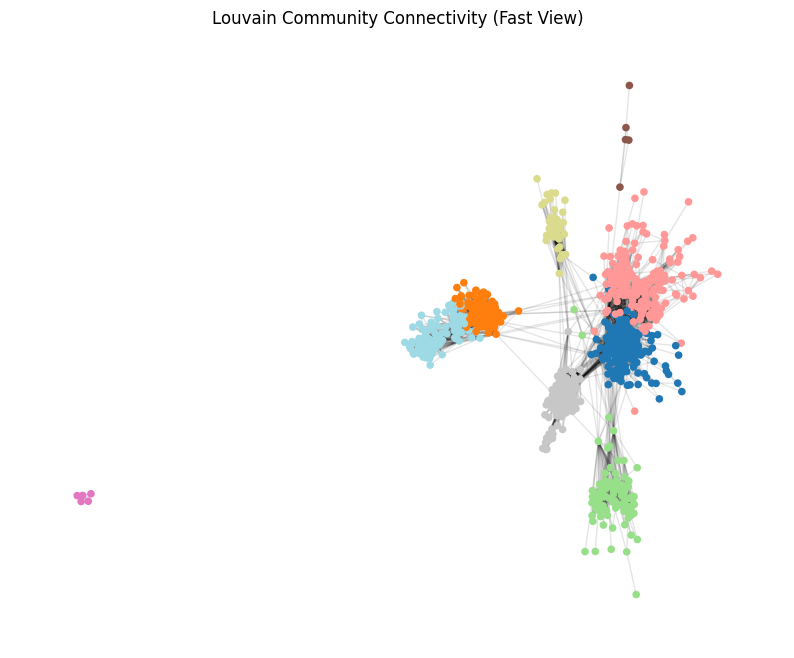

In [12]:
import networkx as nx
import matplotlib.pyplot as plt
import community.community_louvain as community_louvain
import random

# -----------------------------
# 1. Reduce graph size (IMPORTANT)
# -----------------------------
# Take only 1000 nodes (you can change)
nodes_sample = list(G.nodes())[:1000]
G_small = G.subgraph(nodes_sample).copy()

# -----------------------------
# 2. Louvain on smaller graph
# -----------------------------
partition = community_louvain.best_partition(G_small)

print("Total communities:", len(set(partition.values())))

# -----------------------------
# 3. Single fast layout
# -----------------------------
pos = nx.spring_layout(G_small, seed=42)

# -----------------------------
# 4. Assign colors
# -----------------------------
colors = [partition[node] for node in G_small.nodes()]

# -----------------------------
# 5. Draw (FAST VERSION)
# -----------------------------
plt.figure(figsize=(10, 8))

nx.draw_networkx_nodes(
    G_small, pos,
    node_size=20,
    node_color=colors,
    cmap=plt.cm.tab20
)

nx.draw_networkx_edges(
    G_small, pos,
    alpha=0.1
)

plt.title("Louvain Community Connectivity (Fast View)")
plt.axis("off")
plt.show()

c:\Users\admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


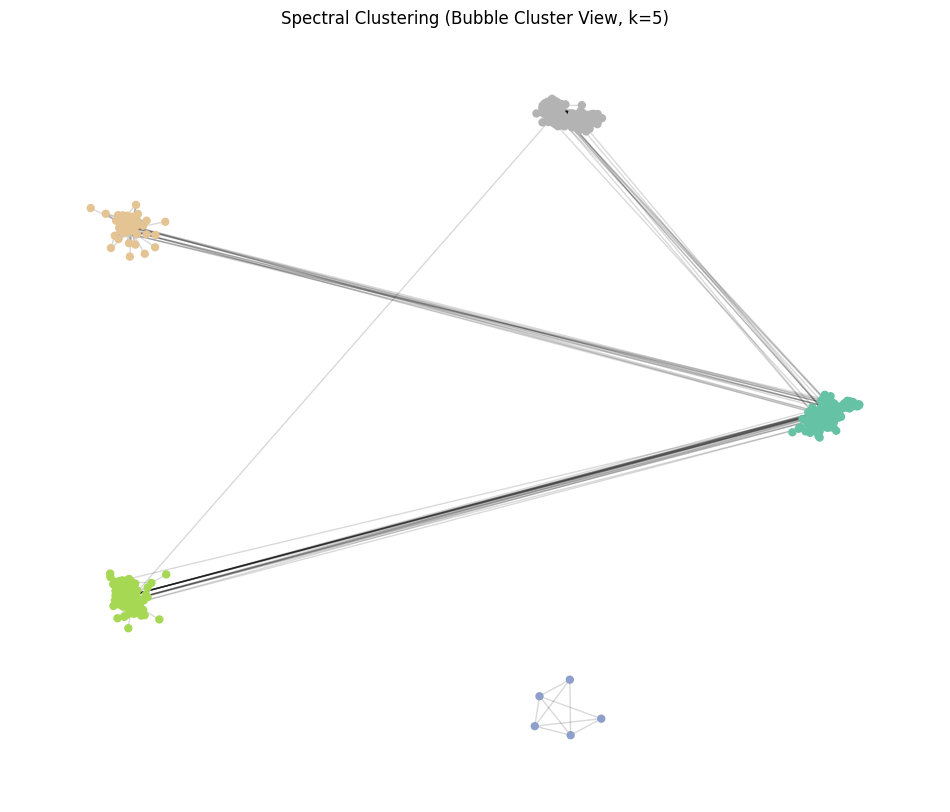

In [14]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import SpectralClustering

# -----------------------------
# 1. Reduce graph size
# -----------------------------
nodes_sample = list(G.nodes())[:1000]
G_small = G.subgraph(nodes_sample).copy()

# -----------------------------
# 2. Spectral Clustering
# -----------------------------
A = nx.to_numpy_array(G_small)

k = 5  # number of clusters

spectral = SpectralClustering(
    n_clusters=k,
    affinity='precomputed',
    random_state=42
)

labels = spectral.fit_predict(A)

node_list = list(G_small.nodes())
partition = {node_list[i]: labels[i] for i in range(len(node_list))}

# -----------------------------
# 3. Group nodes by cluster
# -----------------------------
clusters = {}
for node, c in partition.items():
    clusters.setdefault(c, []).append(node)

# -----------------------------
# 4. Create cluster centers (CIRCLE layout)
# -----------------------------
pos = {}
radius = 10

for i, (cluster, nodes) in enumerate(clusters.items()):
    angle = 2 * np.pi * i / k
    center = np.array([radius * np.cos(angle), radius * np.sin(angle)])

    subgraph = G_small.subgraph(nodes)

    # tight layout inside cluster
    sub_pos = nx.spring_layout(subgraph, seed=42)

    for node in sub_pos:
        pos[node] = sub_pos[node] + center

# -----------------------------
# 5. Draw graph
# -----------------------------
plt.figure(figsize=(12, 10))

colors = [partition[node] for node in G_small.nodes()]

nx.draw_networkx_nodes(
    G_small, pos,
    node_size=25,
    node_color=colors,
    cmap=plt.cm.Set2
)

nx.draw_networkx_edges(
    G_small, pos,
    alpha=0.15
)

plt.title(f"Spectral Clustering (Bubble Cluster View, k={k})")
plt.axis("off")
plt.show()

In [1]:
!pip install igraph leidenalg

   ---------------------------------------- 0.0/3.2 MB ? eta -:--:--
   --------- ------------------------------ 0.8/3.2 MB 6.1 MB/s eta 0:00:01
   ------------------- -------------------- 1.6/3.2 MB 6.8 MB/s eta 0:00:01
   ----------------------------------- ---- 2.9/3.2 MB 5.4 MB/s eta 0:00:01
   ---------------------------------------- 3.2/3.2 MB 5.1 MB/s  0:00:00
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------- ----------------------------- 0.5/2.0 MB 4.9 MB/s eta 0:00:01
   --------------------- ------------------ 1.0/2.0 MB 3.0 MB/s eta 0:00:01
   ------------------------------- -------- 1.6/2.0 MB 2.5 MB/s eta 0:00:01
   ------------------------------------ --- 1.8/2.0 MB 2.2 MB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 2.1 MB/s  0:00:00

   ------------- -------------------------- 1/3 [igraph]
   ------------- -------------------------- 1/3 [igraph]
   ---------------------------------------- 3/3 [leidenalg]



In [3]:
import sys

print(sys.executable)

c:\Users\admin\AppData\Local\Programs\Python\Python313\python.exe


In [4]:
import sys
!{sys.executable} -m pip install igraph leidenalg

  Using cached igraph-1.0.0-cp39-abi3-win_amd64.whl.metadata (4.5 kB)
  Using cached leidenalg-0.12.0-cp38-abi3-win_amd64.whl.metadata (10 kB)
  Using cached texttable-1.7.0-py2.py3-none-any.whl.metadata (9.8 kB)
Using cached igraph-1.0.0-cp39-abi3-win_amd64.whl (3.2 MB)
Using cached leidenalg-0.12.0-cp38-abi3-win_amd64.whl (2.0 MB)
Using cached texttable-1.7.0-py2.py3-none-any.whl (10 kB)



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import sys
!{sys.executable} -m pip install igraph leidenalg python-louvain scikit-learn


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import networkx as nx
import igraph as ig
import leidenalg
from collections import Counter
import time

# ============================================================
# 1. LOAD TWITTER DATASET
# ============================================================

# Change the file path if needed
G = nx.read_edgelist(
    "twitter_combined.txt",
    nodetype=int,
    create_using=nx.Graph()
)

print("================================================")
print("TWITTER DATASET INFORMATION")
print("================================================")

print("Total Nodes:", G.number_of_nodes())
print("Total Edges:", G.number_of_edges())


# ============================================================
# 2. CONVERT NETWORKX GRAPH TO IGRAPH
# ============================================================

print("\nConverting NetworkX graph to igraph...")

# Keep original node IDs
node_list = list(G.nodes())

# Create mapping from Twitter node ID to index
node_to_index = {
    node: i for i, node in enumerate(node_list)
}

# Convert edges to integer indices
edges = [
    (node_to_index[u], node_to_index[v])
    for u, v in G.edges()
]

# Create igraph graph
g_ig = ig.Graph(
    n=len(node_list),
    edges=edges,
    directed=False
)


# ============================================================
# 3. RUN LEIDEN ALGORITHM
# ============================================================

print("\nRunning Leiden Community Detection...")

start_time = time.time()

partition = leidenalg.find_partition(
    g_ig,
    leidenalg.ModularityVertexPartition
)

end_time = time.time()

execution_time = end_time - start_time


# ============================================================
# 4. MAP NODES TO LEIDEN COMMUNITIES
# ============================================================

leiden_partition = {}

for community_id, nodes_in_community in enumerate(partition):
    for node_index in nodes_in_community:
        original_node = node_list[node_index]
        leiden_partition[original_node] = community_id


# ============================================================
# 5. TOTAL COMMUNITIES
# ============================================================

total_communities = len(partition)

print("\n================================================")
print("LEIDEN RESULTS")
print("================================================")

print("Total Leiden Communities:", total_communities)

print(f"Execution Time: {execution_time:.4f} seconds")


# ============================================================
# 6. TOP 10 LARGEST COMMUNITIES
# ============================================================

community_sizes = Counter(leiden_partition.values())

print("\nTop 10 Largest Leiden Communities:")

for community_id, size in community_sizes.most_common(10):
    print(f"Community {community_id}: {size} nodes")


# ============================================================
# 7. SAMPLE NODES FROM DIFFERENT COMMUNITIES
# ============================================================

print("\nSample Nodes from Different Leiden Communities:")

shown = 0
shown_communities = set()

for node, community_id in leiden_partition.items():

    # Show one node from each different community
    if community_id not in shown_communities:

        print(f"Node {node} -> Community {community_id}")

        shown_communities.add(community_id)
        shown += 1

    # Show 10 different communities
    if shown >= 10:
        break


# ============================================================
# 8. MODULARITY SCORE
# ============================================================

# Convert Leiden communities into sets for NetworkX
community_sets = []

for community in partition:
    community_nodes = {
        node_list[node_index]
        for node_index in community
    }

    community_sets.append(community_nodes)


# Calculate modularity
modularity_score = nx.algorithms.community.modularity(
    G,
    community_sets
)

print("\n================================================")
print("COMMUNITY QUALITY EVALUATION")
print("================================================")

print("Modularity Score:", round(modularity_score, 4))


# ============================================================
# 9. SUMMARY
# ============================================================

print("\n================================================")
print("FINAL SUMMARY")
print("================================================")

print("Dataset Nodes:", G.number_of_nodes())
print("Dataset Edges:", G.number_of_edges())
print("Leiden Communities:", total_communities)
print("Modularity Score:", round(modularity_score, 4))
print("Execution Time:", round(execution_time, 4), "seconds")

TWITTER DATASET INFORMATION
Total Nodes: 81306
Total Edges: 1342310

Converting NetworkX graph to igraph...

Running Leiden Community Detection...

LEIDEN RESULTS
Total Leiden Communities: 63
Execution Time: 2.5425 seconds

Top 10 Largest Leiden Communities:
Community 0: 10553 nodes
Community 1: 9383 nodes
Community 2: 6720 nodes
Community 3: 6082 nodes
Community 4: 5136 nodes
Community 5: 3819 nodes
Community 6: 3440 nodes
Community 7: 2887 nodes
Community 8: 2861 nodes
Community 9: 2564 nodes

Sample Nodes from Different Leiden Communities:
Node 17037417 -> Community 0
Node 72680406 -> Community 1
Node 6127252 -> Community 2
Node 214328887 -> Community 3
Node 236575672 -> Community 4
Node 16536215 -> Community 5
Node 14677919 -> Community 6
Node 212018296 -> Community 7
Node 20106852 -> Community 8
Node 14505838 -> Community 9

COMMUNITY QUALITY EVALUATION
Modularity Score: 0.8084

FINAL SUMMARY
Dataset Nodes: 81306
Dataset Edges: 1342310
Leiden Communities: 63
Modularity Score: 0.80

In [10]:
import sys
!{sys.executable} -m pip install networkx python-louvain igraph leidenalg scikit-learn pandas scipy


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



Calculating stability...


FINAL COMMUNITY DETECTION COMPARISON
Algorithm  Nodes  Edges  Communities  Modularity  Execution Time (sec)  Average Community Size  Largest Community  Agreement Score (%)    NMI    ARI  Stability  Accuracy / Quality (%)
  Louvain   5000 105272            5      0.5499                3.6933                 1000.00               2640               100.00 1.0000 1.0000     0.8927                   97.43
 Spectral   5000 105272            5      0.4447                5.4969                 1000.00               2667                79.04 0.7641 0.7898     1.0000                   83.81
   Leiden   5000 105272            6      0.5546                0.2827                  833.33               2678                90.20 0.7631 0.8126     0.8674                   94.41


BEST ALGORITHM
Best Algorithm: Louvain
Quality Score: 97.43 %


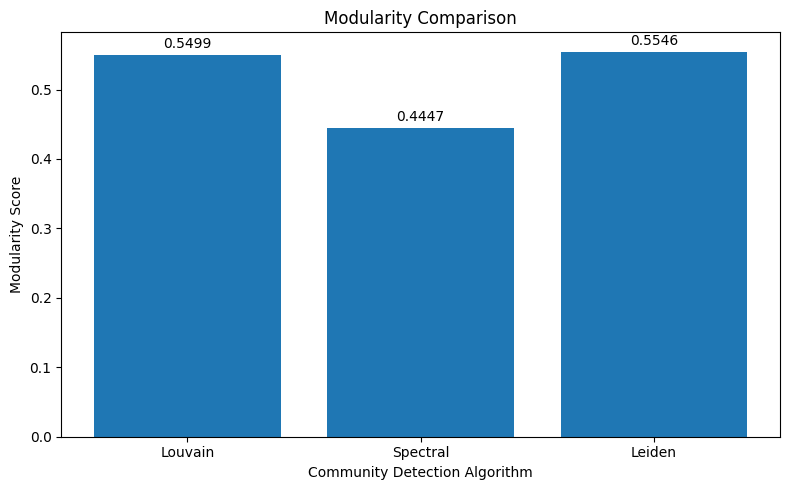

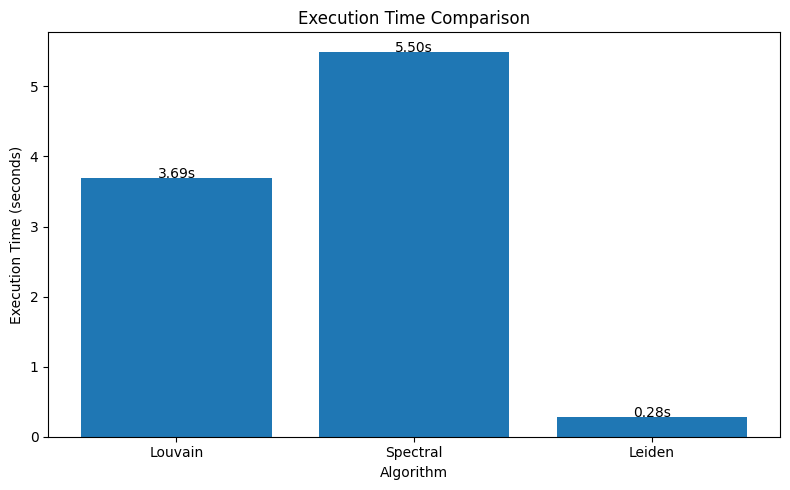

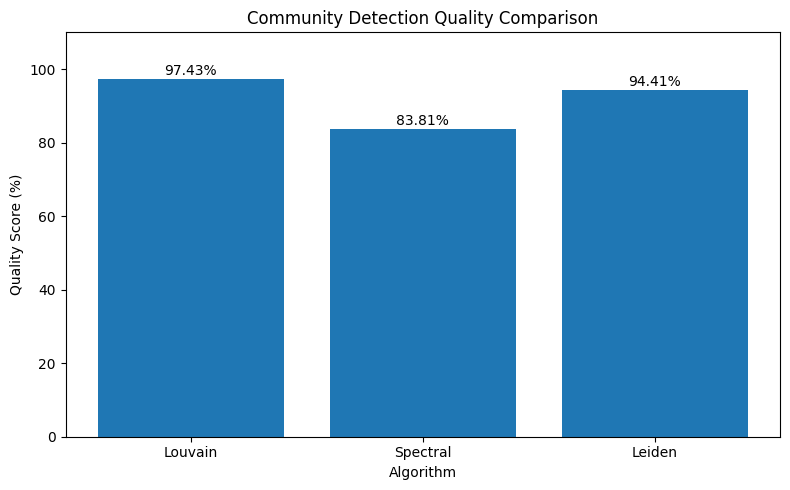

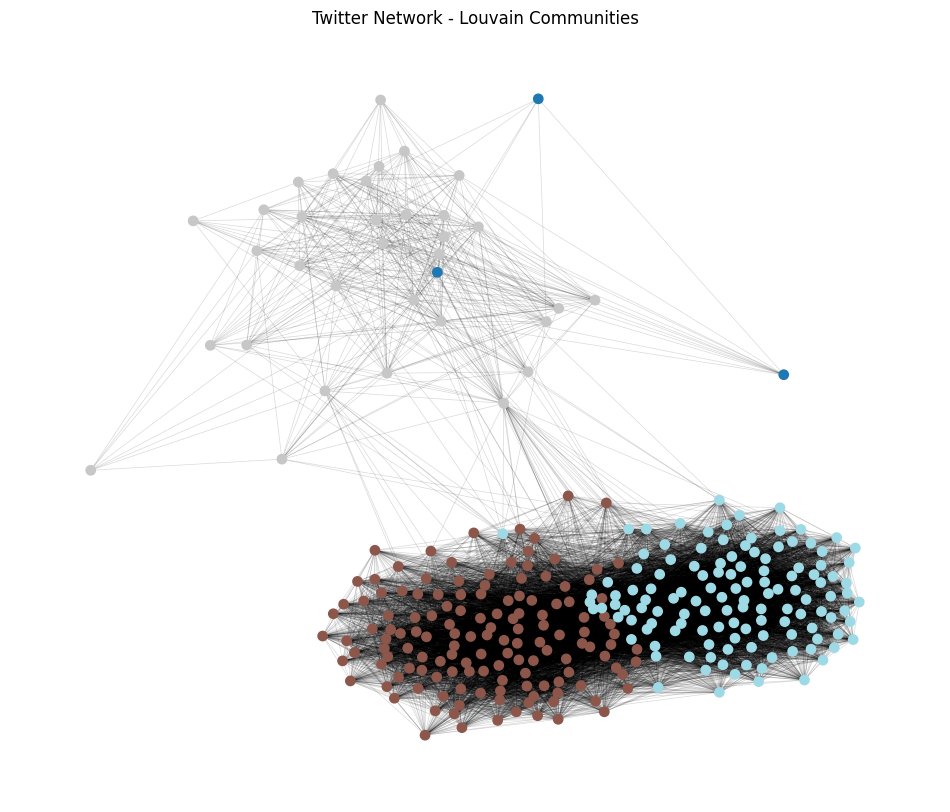

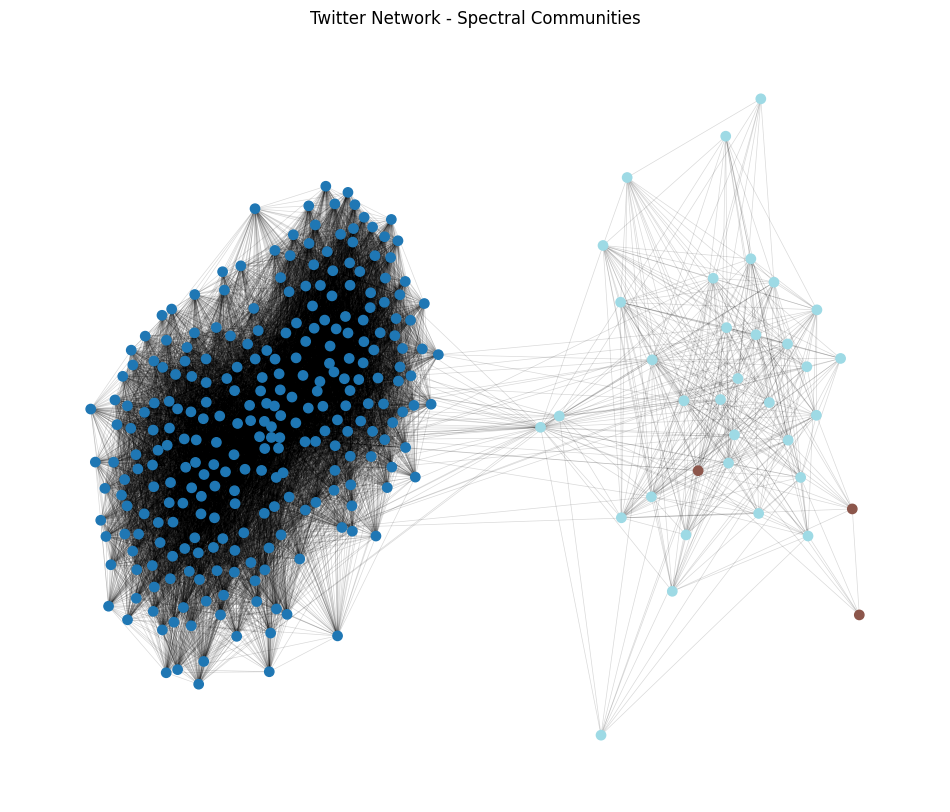

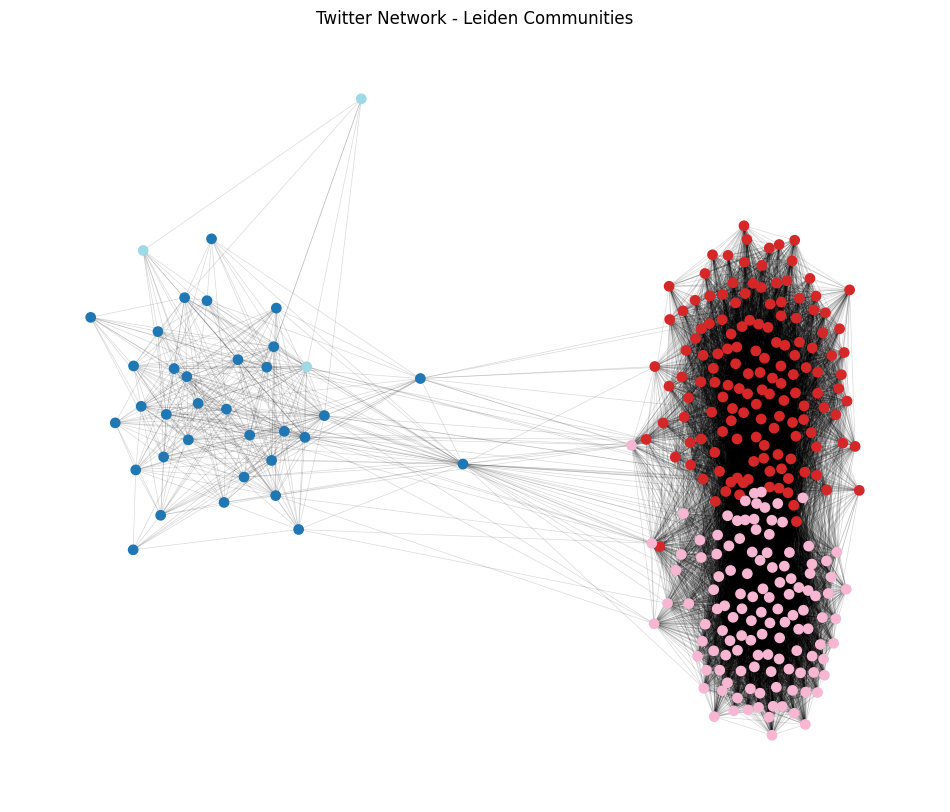

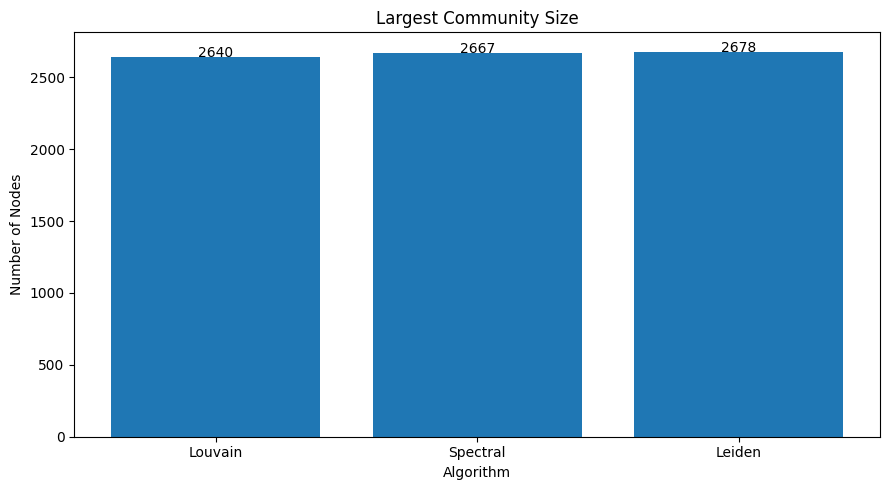

In [13]:
# ============================================================
# FINAL COMPARISON + DIFFERENT COMMUNITY VISUALIZATIONS
# LOUVAIN vs SPECTRAL vs LEIDEN
# ============================================================

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import time

from sklearn.metrics import (
    normalized_mutual_info_score,
    adjusted_rand_score
)

# ============================================================
# 1. GET COMMUNITY SETS
# ============================================================

def get_communities(partition):

    communities = {}

    for node, community_id in partition.items():

        if community_id not in communities:
            communities[community_id] = []

        communities[community_id].append(node)

    return list(communities.values())


louvain_communities = get_communities(
    louvain_partition
)

spectral_communities = get_communities(
    spectral_partition
)

leiden_communities = get_communities(
    leiden_partition
)


# ============================================================
# 2. COMMUNITY STATISTICS
# ============================================================

def get_statistics(
        graph,
        communities,
        execution_time):

    sizes = [
        len(c)
        for c in communities
    ]

    modularity = nx.community.modularity(
        graph,
        communities
    )

    return {
        "Communities": len(communities),
        "Modularity": modularity,
        "Execution Time": execution_time,
        "Average Community Size": np.mean(sizes),
        "Largest Community": max(sizes)
    }


louvain_stats = get_statistics(
    G,
    louvain_communities,
    louvain_time
)

spectral_stats = get_statistics(
    G,
    spectral_communities,
    spectral_time
)

leiden_stats = get_statistics(
    G,
    leiden_communities,
    leiden_time
)


# ============================================================
# 3. LABEL ARRAYS
# ============================================================

nodes = list(G.nodes())

louvain_labels = np.array([
    louvain_partition[node]
    for node in nodes
])

spectral_labels = np.array([
    spectral_partition[node]
    for node in nodes
])

leiden_labels = np.array([
    leiden_partition[node]
    for node in nodes
])


# ============================================================
# 4. NMI + ARI
# ============================================================

spectral_nmi = normalized_mutual_info_score(
    louvain_labels,
    spectral_labels
)

spectral_ari = adjusted_rand_score(
    louvain_labels,
    spectral_labels
)

leiden_nmi = normalized_mutual_info_score(
    louvain_labels,
    leiden_labels
)

leiden_ari = adjusted_rand_score(
    louvain_labels,
    leiden_labels
)


# ============================================================
# 5. AGREEMENT SCORE
# ============================================================

def calculate_agreement(
        reference,
        predicted):

    # Build contingency matrix
    ref_values = np.unique(reference)
    pred_values = np.unique(predicted)

    matrix = np.zeros(
        (len(ref_values), len(pred_values))
    )

    for i, ref in enumerate(ref_values):

        for j, pred in enumerate(pred_values):

            matrix[i, j] = np.sum(
                (reference == ref) &
                (predicted == pred)
            )

    from scipy.optimize import linear_sum_assignment

    rows, cols = linear_sum_assignment(
        -matrix
    )

    matched = matrix[
        rows,
        cols
    ].sum()

    return (
        matched /
        len(reference)
    ) * 100


spectral_agreement = calculate_agreement(
    louvain_labels,
    spectral_labels
)

leiden_agreement = calculate_agreement(
    louvain_labels,
    leiden_labels
)


# ============================================================
# 6. STABILITY
#
# Run algorithms multiple times and compare results.
# ============================================================

def louvain_stability(graph, runs=3):

    results = []

    for seed in range(runs):

        partition = community_louvain.best_partition(
            graph,
            random_state=seed
        )

        labels = [
            partition[node]
            for node in nodes
        ]

        results.append(labels)

    scores = []

    for i in range(1, runs):

        score = normalized_mutual_info_score(
            results[0],
            results[i]
        )

        scores.append(score)

    return np.mean(scores)


def leiden_stability(graph, runs=3):

    results = []

    # Convert graph
    node_list = list(graph.nodes())

    node_index = {
        node: i
        for i, node in enumerate(node_list)
    }

    edges = [
        (
            node_index[u],
            node_index[v]
        )
        for u, v in graph.edges()
    ]

    ig_graph = ig.Graph(
        n=len(node_list),
        edges=edges
    )

    for seed in range(runs):

        partition = leidenalg.find_partition(
            ig_graph,
            leidenalg.ModularityVertexPartition,
            seed=seed
        )

        labels = np.zeros(
            len(node_list),
            dtype=int
        )

        for community_id, community_nodes in enumerate(
                partition):

            for node_id in community_nodes:

                labels[node_id] = community_id

        results.append(labels)

    scores = []

    for i in range(1, runs):

        score = normalized_mutual_info_score(
            results[0],
            results[i]
        )

        scores.append(score)

    return np.mean(scores)


def spectral_stability(
        adjacency_matrix,
        n_clusters,
        runs=3):

    results = []

    for seed in range(runs):

        model = SpectralClustering(
            n_clusters=n_clusters,
            affinity="precomputed",
            assign_labels="kmeans",
            random_state=seed,
            n_init=10
        )

        labels = model.fit_predict(
            adjacency_matrix
        )

        results.append(labels)

    scores = []

    for i in range(1, runs):

        score = normalized_mutual_info_score(
            results[0],
            results[i]
        )

        scores.append(score)

    return np.mean(scores)


print("\nCalculating stability...")

louvain_stab = louvain_stability(G)

leiden_stab = leiden_stability(G)

spectral_stab = spectral_stability(
    adjacency_matrix,
    n_clusters
)


# ============================================================
# 7. COMMUNITY QUALITY / ACCURACY SCORE
#
# IMPORTANT:
# This is NOT ground-truth classification accuracy.
#
# It is a composite community-quality score.
# ============================================================

max_modularity = max(
    louvain_stats["Modularity"],
    spectral_stats["Modularity"],
    leiden_stats["Modularity"]
)


def quality_score(
        modularity,
        agreement,
        stability):

    normalized_modularity = (
        modularity /
        max_modularity
    )

    return (
        (
            0.50 * normalized_modularity
        )
        +
        (
            0.30 * (agreement / 100)
        )
        +
        (
            0.20 * stability
        )
    ) * 100


louvain_quality = quality_score(
    louvain_stats["Modularity"],
    100,
    louvain_stab
)

spectral_quality = quality_score(
    spectral_stats["Modularity"],
    spectral_agreement,
    spectral_stab
)

leiden_quality = quality_score(
    leiden_stats["Modularity"],
    leiden_agreement,
    leiden_stab
)


# ============================================================
# 8. FINAL COMPARISON TABLE
# ============================================================

comparison = pd.DataFrame({

    "Algorithm": [
        "Louvain",
        "Spectral",
        "Leiden"
    ],

    "Nodes": [
        G.number_of_nodes(),
        G.number_of_nodes(),
        G.number_of_nodes()
    ],

    "Edges": [
        G.number_of_edges(),
        G.number_of_edges(),
        G.number_of_edges()
    ],

    "Communities": [
        louvain_stats["Communities"],
        spectral_stats["Communities"],
        leiden_stats["Communities"]
    ],

    "Modularity": [
        round(louvain_stats["Modularity"], 4),
        round(spectral_stats["Modularity"], 4),
        round(leiden_stats["Modularity"], 4)
    ],

    "Execution Time (sec)": [
        round(louvain_stats["Execution Time"], 4),
        round(spectral_stats["Execution Time"], 4),
        round(leiden_stats["Execution Time"], 4)
    ],

    "Average Community Size": [
        round(louvain_stats["Average Community Size"], 2),
        round(spectral_stats["Average Community Size"], 2),
        round(leiden_stats["Average Community Size"], 2)
    ],

    "Largest Community": [
        louvain_stats["Largest Community"],
        spectral_stats["Largest Community"],
        leiden_stats["Largest Community"]
    ],

    "Agreement Score (%)": [
        100.00,
        round(spectral_agreement, 2),
        round(leiden_agreement, 2)
    ],

    "NMI": [
        1.0000,
        round(spectral_nmi, 4),
        round(leiden_nmi, 4)
    ],

    "ARI": [
        1.0000,
        round(spectral_ari, 4),
        round(leiden_ari, 4)
    ],

    "Stability": [
        round(louvain_stab, 4),
        round(spectral_stab, 4),
        round(leiden_stab, 4)
    ],

    "Accuracy / Quality (%)": [
        round(louvain_quality, 2),
        round(spectral_quality, 2),
        round(leiden_quality, 2)
    ]
})


# ============================================================
# 9. DISPLAY TABLE
# ============================================================

print("\n")
print("=" * 150)
print("FINAL COMMUNITY DETECTION COMPARISON")
print("=" * 150)

print(
    comparison.to_string(index=False)
)


# ============================================================
# 10. FIND BEST ALGORITHM
# ============================================================

best_index = comparison[
    "Accuracy / Quality (%)"
].idxmax()

best_algorithm = comparison.loc[
    best_index,
    "Algorithm"
]

print("\n")
print("=" * 75)
print("BEST ALGORITHM")
print("=" * 75)

print(
    "Best Algorithm:",
    best_algorithm
)

print(
    "Quality Score:",
    comparison.loc[
        best_index,
        "Accuracy / Quality (%)"
    ],
    "%"
)


# ============================================================
# 11. MODULARITY GRAPH
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Algorithm"],
    comparison["Modularity"]
)

plt.title(
    "Modularity Comparison"
)

plt.xlabel(
    "Community Detection Algorithm"
)

plt.ylabel(
    "Modularity Score"
)

for i, value in enumerate(
        comparison["Modularity"]):

    plt.text(
        i,
        value + 0.01,
        f"{value:.4f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


# ============================================================
# 12. EXECUTION TIME GRAPH
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Algorithm"],
    comparison["Execution Time (sec)"]
)

plt.title(
    "Execution Time Comparison"
)

plt.xlabel(
    "Algorithm"
)

plt.ylabel(
    "Execution Time (seconds)"
)

for i, value in enumerate(
        comparison["Execution Time (sec)"]):

    plt.text(
        i,
        value,
        f"{value:.2f}s",
        ha="center"
    )

plt.tight_layout()
plt.show()


# ============================================================
# 13. ACCURACY / QUALITY GRAPH
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Algorithm"],
    comparison["Accuracy / Quality (%)"]
)

plt.title(
    "Community Detection Quality Comparison"
)

plt.xlabel(
    "Algorithm"
)

plt.ylabel(
    "Quality Score (%)"
)

for i, value in enumerate(
        comparison["Accuracy / Quality (%)"]):

    plt.text(
        i,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.ylim(0, 110)

plt.tight_layout()
plt.show()


# ============================================================
# 14. DIFFERENT COMMUNITY VISUALIZATION
#
# IMPORTANT:
# Each algorithm gets its OWN layout.
# Therefore the diagrams will NOT look identical.
# ============================================================

VISUAL_NODES = 300


def create_visual_graph(
        graph,
        partition):

    # Select 300 nodes with highest degree
    selected = sorted(
        graph.degree,
        key=lambda x: x[1],
        reverse=True
    )[:VISUAL_NODES]

    selected_nodes = [
        node
        for node, degree in selected
    ]

    visual_graph = graph.subgraph(
        selected_nodes
    ).copy()

    return visual_graph


# ============================================================
# LOUVAIN VISUALIZATION
# ============================================================

G_louvain = create_visual_graph(
    G,
    louvain_partition
)

# Layout specifically based on Louvain structure
pos_louvain = nx.spring_layout(
    G_louvain,
    seed=10,
    k=0.7,
    iterations=80
)

plt.figure(figsize=(12, 10))

louvain_node_colors = [
    louvain_partition[node]
    for node in G_louvain.nodes()
]

nx.draw_networkx_edges(
    G_louvain,
    pos_louvain,
    alpha=0.15,
    width=0.5
)

nx.draw_networkx_nodes(
    G_louvain,
    pos_louvain,
    node_size=45,
    node_color=louvain_node_colors,
    cmap=plt.cm.tab20
)

plt.title(
    "Twitter Network - Louvain Communities"
)

plt.axis("off")

plt.show()


# ============================================================
# SPECTRAL VISUALIZATION
# ============================================================

G_spectral = create_visual_graph(
    G,
    spectral_partition
)

# DIFFERENT layout seed
pos_spectral = nx.spring_layout(
    G_spectral,
    seed=99,
    k=0.9,
    iterations=100
)

plt.figure(figsize=(12, 10))

spectral_node_colors = [
    spectral_partition[node]
    for node in G_spectral.nodes()
]

nx.draw_networkx_edges(
    G_spectral,
    pos_spectral,
    alpha=0.15,
    width=0.5
)

nx.draw_networkx_nodes(
    G_spectral,
    pos_spectral,
    node_size=45,
    node_color=spectral_node_colors,
    cmap=plt.cm.tab20
)

plt.title(
    "Twitter Network - Spectral Communities"
)

plt.axis("off")

plt.show()


# ============================================================
# LEIDEN VISUALIZATION
# ============================================================

G_leiden = create_visual_graph(
    G,
    leiden_partition
)

# DIFFERENT layout seed
pos_leiden = nx.spring_layout(
    G_leiden,
    seed=2026,
    k=0.6,
    iterations=100
)

plt.figure(figsize=(12, 10))

leiden_node_colors = [
    leiden_partition[node]
    for node in G_leiden.nodes()
]

nx.draw_networkx_edges(
    G_leiden,
    pos_leiden,
    alpha=0.15,
    width=0.5
)

nx.draw_networkx_nodes(
    G_leiden,
    pos_leiden,
    node_size=45,
    node_color=leiden_node_colors,
    cmap=plt.cm.tab20
)

plt.title(
    "Twitter Network - Leiden Communities"
)

plt.axis("off")

plt.show()


# ============================================================
# 15. COMMUNITY SIZE COMPARISON
# ============================================================

plt.figure(figsize=(9, 5))

plt.bar(
    comparison["Algorithm"],
    comparison["Largest Community"]
)

plt.title(
    "Largest Community Size"
)

plt.xlabel(
    "Algorithm"
)

plt.ylabel(
    "Number of Nodes"
)

for i, value in enumerate(
        comparison["Largest Community"]):

    plt.text(
        i,
        value,
        str(value),
        ha="center"
    )

plt.tight_layout()
plt.show()

In [1]:
!pip install torch-geometric scikit-learn networkx matplotlib pandas

  Using cached torch_geometric-2.8.0.post1-py3-none-any.whl.metadata (64 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)


ERROR: Could not install packages due to an OSError: ("Connection broken: OSError(28, 'No space left on device')", OSError(28, 'No space left on device'))

Exception ignored while calling deallocator <function _TemporaryFileCloser.__del__ at 0x000001EA663B0A90>:
Traceback (most recent call last):
  File "C:\Users\admin\AppData\Local\Programs\Python\Python314\Lib\tempfile.py", line 482, in __del__
    self.cleanup()
  File "C:\Users\admin\AppData\Local\Programs\Python\Python314\Lib\tempfile.py", line 461, in cleanup
    self.file.close()
OSError: [Errno 28] No space left on device


The history saving thread hit an unexpected error (OperationalError('database or disk is full')).History will not be written to the database.
        GNN COMMUNITY DETECTION - TWITTER DATASET

Loading Twitter dataset...
Original Nodes : 81306
Original Edges : 1342310

Finding largest connected component...
LCC Nodes      : 81306
LCC Edges      : 1342310

Creating connected 5000-node graph...

FINAL GRAPH USED FOR GNN
--------------------------------------------------
Nodes : 5000
Edges : 129828
Connected : True
Average Degree : 51.93

Extracting graph-based node features...
Feature Matrix Shape : torch.Size([5000, 5])

Features used:
1. Degree
2. Clustering Coefficient
3. PageRank
4. Core Number
5. Local Density

Feature extraction time: 25.362 seconds

PyTorch Geometric Graph
--------------------------------------------------
Nodes : 5000
Edges : 259656
Features per node : 5

Training Device: cpu

                 TRAINING GCN / GAE
Epoch 001 | Reconstruction Loss: 1.1132
Epoch 010 | 

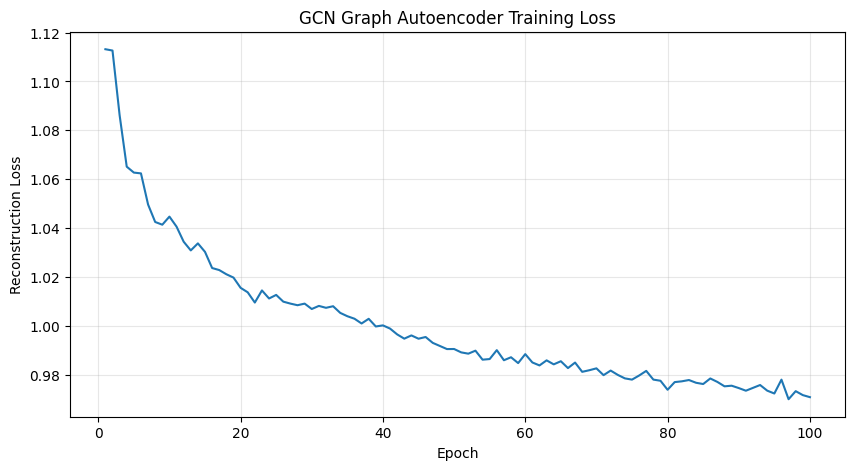

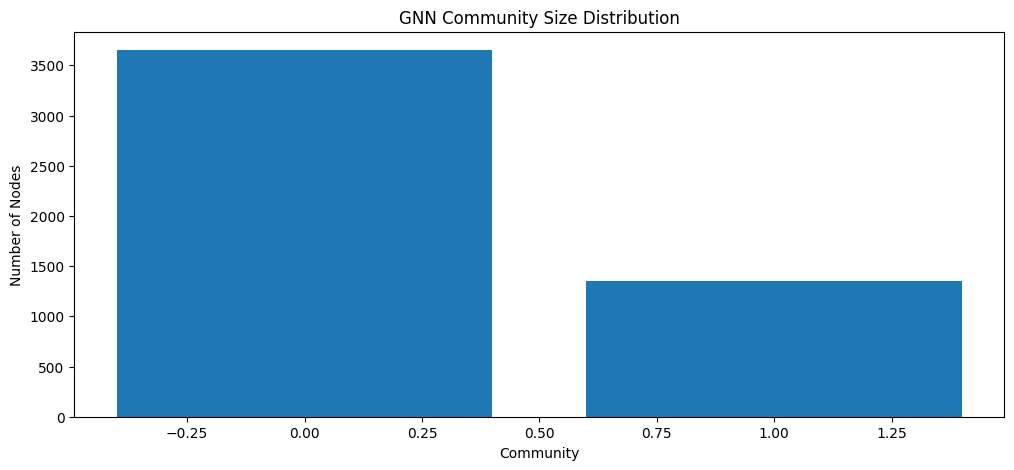


Generating 2D GNN embedding visualization...


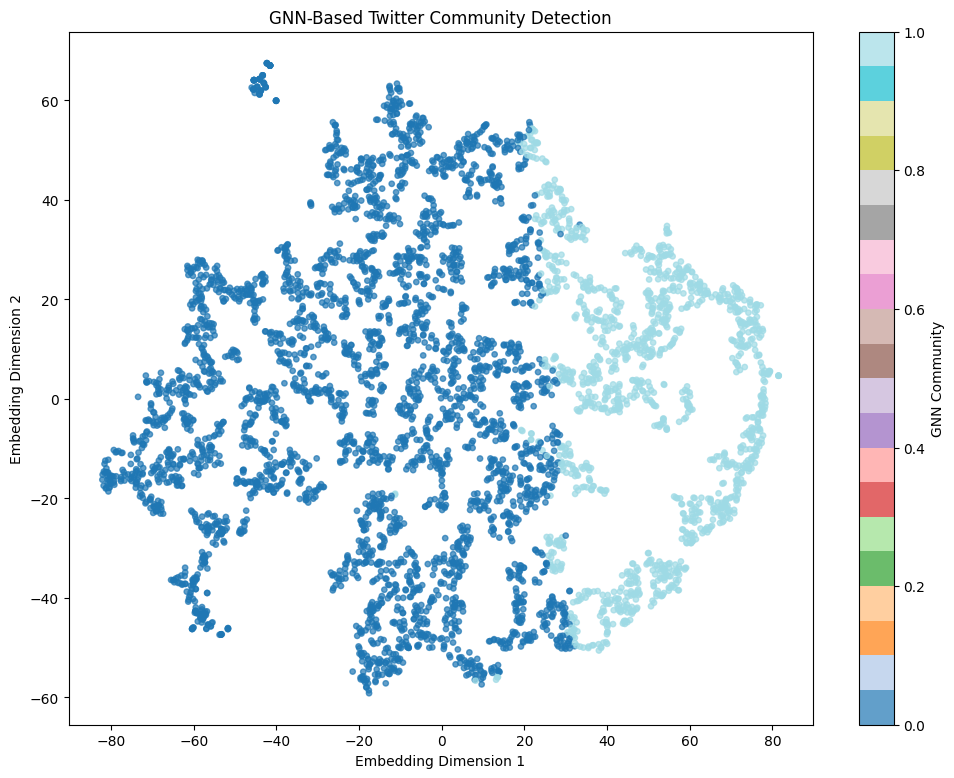


                     FINAL GNN RESULTS
                Metric         GNN
                 Nodes   5000.0000
                 Edges 129828.0000
       GNN Communities      2.0000
            Modularity      0.1595
  Execution Time (sec)     39.4699
Average Community Size   2500.0000
     Largest Community   3652.0000
Community Size Std Dev   1152.0000
      Silhouette Score      0.3952

Files saved:
1. gnn_community_results.csv
2. gnn_node_embeddings.npy

                 GNN PROCESS COMPLETED


In [2]:
# ================================================================
# GNN COMMUNITY DETECTION ON TWITTER SOCIAL NETWORK
# GCN + GRAPH AUTOENCODER + K-MEANS
# ================================================================

import os
import time
import random
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from collections import Counter

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.data import Data
from torch_geometric.nn import GCNConv, GAE


# ================================================================
# 1. SETTINGS
# ================================================================

DATASET_PATH = r"D:\GNN Mini project\twitter_combined.txt"

NUM_NODES = 5000
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("=" * 75)
print("        GNN COMMUNITY DETECTION - TWITTER DATASET")
print("=" * 75)


# ================================================================
# 2. LOAD TWITTER DATASET
# ================================================================

print("\nLoading Twitter dataset...")

G_original = nx.read_edgelist(
    DATASET_PATH,
    nodetype=int
)

print("Original Nodes :", G_original.number_of_nodes())
print("Original Edges :", G_original.number_of_edges())


# ================================================================
# 3. FIND LARGEST CONNECTED COMPONENT
# ================================================================

print("\nFinding largest connected component...")

largest_component = max(
    nx.connected_components(G_original),
    key=len
)

G_lcc = G_original.subgraph(largest_component).copy()

print("LCC Nodes      :", G_lcc.number_of_nodes())
print("LCC Edges      :", G_lcc.number_of_edges())


# ================================================================
# 4. CREATE CONNECTED 5000-NODE SUBGRAPH
# ================================================================

print("\nCreating connected 5000-node graph...")

# Start BFS from a fixed node
start_node = list(G_lcc.nodes())[0]

selected_nodes = []
visited = {start_node}
queue = [start_node]

while queue and len(selected_nodes) < NUM_NODES:

    current = queue.pop(0)
    selected_nodes.append(current)

    for neighbor in G_lcc.neighbors(current):

        if neighbor not in visited:

            visited.add(neighbor)
            queue.append(neighbor)

            if len(selected_nodes) >= NUM_NODES:
                break


# Create induced subgraph
G = G_lcc.subgraph(selected_nodes).copy()

# If BFS produced more/less due to graph structure
if G.number_of_nodes() > NUM_NODES:
    selected_nodes = selected_nodes[:NUM_NODES]
    G = G_lcc.subgraph(selected_nodes).copy()


print("\nFINAL GRAPH USED FOR GNN")
print("-" * 50)
print("Nodes :", G.number_of_nodes())
print("Edges :", G.number_of_edges())
print("Connected :", nx.is_connected(G))
print("Average Degree :", round(
    sum(dict(G.degree()).values()) / G.number_of_nodes(), 2
))


# ================================================================
# 5. CREATE NODE INDEX MAPPING
# ================================================================

nodes = list(G.nodes())

node_to_idx = {
    node: i for i, node in enumerate(nodes)
}

idx_to_node = {
    i: node for i, node in enumerate(nodes)
}


# ================================================================
# 6. NODE FEATURE EXTRACTION
# ================================================================

print("\nExtracting graph-based node features...")

feature_start = time.time()

# ------------------------------------------------
# Feature 1: Degree
# ------------------------------------------------

degree_dict = dict(G.degree())


# ------------------------------------------------
# Feature 2: Clustering coefficient
# ------------------------------------------------

clustering_dict = nx.clustering(G)


# ------------------------------------------------
# Feature 3: PageRank
# ------------------------------------------------

pagerank_dict = nx.pagerank(
    G,
    alpha=0.85,
    max_iter=100
)


# ------------------------------------------------
# Feature 4: Core number
# ------------------------------------------------

core_dict = nx.core_number(G)


# ------------------------------------------------
# Feature 5: Local density
# ------------------------------------------------

local_density = {}

for node in nodes:

    neighbors = list(G.neighbors(node))

    degree = len(neighbors)

    if degree < 2:
        density = 0.0

    else:

        possible_edges = degree * (degree - 1) / 2

        actual_edges = G.subgraph(neighbors).number_of_edges()

        density = actual_edges / possible_edges

    local_density[node] = density


# ------------------------------------------------
# Construct feature matrix
# ------------------------------------------------

features = []

for node in nodes:

    features.append([
        degree_dict[node],
        clustering_dict[node],
        pagerank_dict[node],
        core_dict[node],
        local_density[node]
    ])


X = np.array(features, dtype=np.float32)


# ------------------------------------------------
# Normalize features
# ------------------------------------------------

scaler = StandardScaler()

X = scaler.fit_transform(X)

X = torch.tensor(
    X,
    dtype=torch.float
)


print("Feature Matrix Shape :", X.shape)

print("""
Features used:
1. Degree
2. Clustering Coefficient
3. PageRank
4. Core Number
5. Local Density
""")


print(
    "Feature extraction time:",
    round(time.time() - feature_start, 3),
    "seconds"
)


# ================================================================
# 7. CREATE EDGE INDEX
# ================================================================

edge_list = []

for u, v in G.edges():

    ui = node_to_idx[u]
    vi = node_to_idx[v]

    edge_list.append([ui, vi])
    edge_list.append([vi, ui])


edge_index = torch.tensor(
    edge_list,
    dtype=torch.long
).t().contiguous()


# ================================================================
# 8. CREATE PYTORCH GEOMETRIC DATA
# ================================================================

data = Data(
    x=X,
    edge_index=edge_index
)

print("\nPyTorch Geometric Graph")
print("-" * 50)
print("Nodes :", data.num_nodes)
print("Edges :", data.num_edges)
print("Features per node :", data.num_node_features)


# ================================================================
# 9. DEFINE GCN ENCODER
# ================================================================

class GCNEncoder(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim,
        embedding_dim
    ):

        super().__init__()

        self.conv1 = GCNConv(
            input_dim,
            hidden_dim
        )

        self.conv2 = GCNConv(
            hidden_dim,
            embedding_dim
        )


    def forward(
        self,
        x,
        edge_index
    ):

        x = self.conv1(
            x,
            edge_index
        )

        x = F.relu(x)

        x = F.dropout(
            x,
            p=0.2,
            training=self.training
        )

        x = self.conv2(
            x,
            edge_index
        )

        return x


# ================================================================
# 10. CREATE GRAPH AUTOENCODER
# ================================================================

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("\nTraining Device:", device)


model = GAE(
    GCNEncoder(
        input_dim=data.num_node_features,
        hidden_dim=32,
        embedding_dim=16
    )
).to(device)


data = data.to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01,
    weight_decay=5e-4
)


# ================================================================
# 11. TRAIN GNN
# ================================================================

print("\n" + "=" * 75)
print("                 TRAINING GCN / GAE")
print("=" * 75)

gnn_start = time.time()

EPOCHS = 100

loss_history = []


for epoch in range(1, EPOCHS + 1):

    model.train()

    optimizer.zero_grad()

    z = model.encode(
        data.x,
        data.edge_index
    )

    loss = model.recon_loss(
        z,
        data.edge_index
    )

    loss.backward()

    optimizer.step()

    loss_history.append(
        loss.item()
    )


    if epoch == 1 or epoch % 10 == 0:

        print(
            f"Epoch {epoch:03d} | "
            f"Reconstruction Loss: {loss.item():.4f}"
        )


gnn_time = time.time() - gnn_start


print("\nGNN Training Time:",
      round(gnn_time, 4),
      "seconds")


# ================================================================
# 12. GENERATE NODE EMBEDDINGS
# ================================================================

model.eval()

with torch.no_grad():

    embeddings = model.encode(
        data.x,
        data.edge_index
    )


embeddings = embeddings.cpu().numpy()


print("\n" + "=" * 75)
print("                  GNN NODE EMBEDDINGS")
print("=" * 75)

print("Embedding Shape :", embeddings.shape)

print("\nSample Node Embeddings:")

for i in range(10):

    print(
        f"Node {idx_to_node[i]} ->",
        np.round(
            embeddings[i][:8],
            4
        )
    )


# ================================================================
# 13. DETERMINE NUMBER OF GNN COMMUNITIES
# ================================================================
#
# For comparison, use the number of communities found by Leiden
# if your Leiden result is already available.
#
# Otherwise, estimate a suitable K using silhouette score.
# ================================================================

print("\n" + "=" * 75)
print("             FINDING GNN COMMUNITY COUNT")
print("=" * 75)


candidate_k = range(2, 11)

silhouette_results = {}

for k in candidate_k:

    km = KMeans(
        n_clusters=k,
        random_state=SEED,
        n_init=10
    )

    labels_temp = km.fit_predict(
        embeddings
    )

    score = silhouette_score(
        embeddings,
        labels_temp
    )

    silhouette_results[k] = score

    print(
        f"K = {k:2d} | "
        f"Silhouette = {score:.4f}"
    )


best_k = max(
    silhouette_results,
    key=silhouette_results.get
)

print(
    "\nSelected number of GNN communities:",
    best_k
)


# ================================================================
# 14. K-MEANS ON GNN EMBEDDINGS
# ================================================================

print("\nRunning K-Means on GNN embeddings...")

cluster_start = time.time()

kmeans = KMeans(
    n_clusters=best_k,
    random_state=SEED,
    n_init=20
)

gnn_labels = kmeans.fit_predict(
    embeddings
)

cluster_time = time.time() - cluster_start


# ================================================================
# 15. COMMUNITY INFORMATION
# ================================================================

gnn_communities = {}

for node, label in zip(
    nodes,
    gnn_labels
):

    gnn_communities.setdefault(
        label,
        []
    ).append(node)


print("\n" + "=" * 75)
print("              GNN COMMUNITY RESULTS")
print("=" * 75)

print(
    "Total GNN Communities:",
    len(gnn_communities)
)


# ================================================================
# 16. COMMUNITY SIZES
# ================================================================

community_sizes = {
    c: len(nodelist)
    for c, nodelist
    in gnn_communities.items()
}


sorted_communities = sorted(
    community_sizes.items(),
    key=lambda x: x[1],
    reverse=True
)


print("\nTop 10 Largest GNN Communities:")

for community, size in sorted_communities[:10]:

    print(
        f"Community {community}: "
        f"{size} nodes"
    )


# ================================================================
# 17. SAMPLE NODES FROM DIFFERENT COMMUNITIES
# ================================================================

print("\n" + "-" * 75)
print("Sample Nodes from Different GNN Communities:")

shown = 0

for community, nodes_list in sorted(
    gnn_communities.items()
):

    node = nodes_list[0]

    print(
        f"Node {node} -> "
        f"GNN Community {community}"
    )

    shown += 1

    if shown >= 10:
        break


# ================================================================
# 18. COMMUNITY METRICS
# ================================================================

print("\n" + "=" * 75)
print("                 GNN COMMUNITY METRICS")
print("=" * 75)


# ------------------------------------------------
# Modularity
# ------------------------------------------------

community_sets = [
    set(v)
    for v in gnn_communities.values()
]

modularity = nx.community.modularity(
    G,
    community_sets
)


# ------------------------------------------------
# Average community size
# ------------------------------------------------

average_community_size = np.mean(
    list(community_sizes.values())
)


# ------------------------------------------------
# Largest community
# ------------------------------------------------

largest_community = max(
    community_sizes.values()
)


# ------------------------------------------------
# Community size standard deviation
# ------------------------------------------------

community_size_std = np.std(
    list(community_sizes.values())
)


# ------------------------------------------------
# Silhouette score
# ------------------------------------------------

final_silhouette = silhouette_score(
    embeddings,
    gnn_labels
)


print(
    "Modularity               :",
    round(modularity, 4)
)

print(
    "Communities              :",
    len(gnn_communities)
)

print(
    "Execution Time           :",
    round(gnn_time + cluster_time, 4),
    "seconds"
)

print(
    "Average Community Size   :",
    round(average_community_size, 2)
)

print(
    "Largest Community        :",
    largest_community
)

print(
    "Community Size Std Dev   :",
    round(community_size_std, 2)
)

print(
    "Silhouette Score         :",
    round(final_silhouette, 4)
)


# ================================================================
# 19. LOSS GRAPH
# ================================================================

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, EPOCHS + 1),
    loss_history
)

plt.xlabel("Epoch")
plt.ylabel("Reconstruction Loss")

plt.title(
    "GCN Graph Autoencoder Training Loss"
)

plt.grid(alpha=0.3)

plt.show()


# ================================================================
# 20. COMMUNITY SIZE GRAPH
# ================================================================

plt.figure(figsize=(12, 5))

community_ids = [
    x[0]
    for x in sorted_communities
]

sizes = [
    x[1]
    for x in sorted_communities
]

plt.bar(
    range(len(sizes)),
    sizes
)

plt.xlabel("Community")
plt.ylabel("Number of Nodes")

plt.title(
    "GNN Community Size Distribution"
)

plt.show()


# ================================================================
# 21. 2D VISUALIZATION OF GNN EMBEDDINGS
# ================================================================

from sklearn.manifold import TSNE

print("\nGenerating 2D GNN embedding visualization...")

# Use PCA first to reduce dimensionality
from sklearn.decomposition import PCA

pca = PCA(
    n_components=10,
    random_state=SEED
)

embedding_reduced = pca.fit_transform(
    embeddings
)


tsne = TSNE(
    n_components=2,
    random_state=SEED,
    perplexity=30,
    max_iter=1000
)

embedding_2d = tsne.fit_transform(
    embedding_reduced
)


plt.figure(figsize=(12, 9))

scatter = plt.scatter(
    embedding_2d[:, 0],
    embedding_2d[:, 1],
    c=gnn_labels,
    s=15,
    alpha=0.7,
    cmap="tab20"
)

plt.colorbar(
    scatter,
    label="GNN Community"
)

plt.xlabel("Embedding Dimension 1")
plt.ylabel("Embedding Dimension 2")

plt.title(
    "GNN-Based Twitter Community Detection"
)

plt.show()


# ================================================================
# 22. FINAL RESULT TABLE
# ================================================================

results = pd.DataFrame({

    "Metric": [
        "Nodes",
        "Edges",
        "GNN Communities",
        "Modularity",
        "Execution Time (sec)",
        "Average Community Size",
        "Largest Community",
        "Community Size Std Dev",
        "Silhouette Score"
    ],

    "GNN": [

        G.number_of_nodes(),

        G.number_of_edges(),

        len(gnn_communities),

        round(modularity, 4),

        round(
            gnn_time + cluster_time,
            4
        ),

        round(
            average_community_size,
            2
        ),

        largest_community,

        round(
            community_size_std,
            2
        ),

        round(
            final_silhouette,
            4
        )
    ]
})


print("\n" + "=" * 75)
print("                     FINAL GNN RESULTS")
print("=" * 75)

print(
    results.to_string(
        index=False
    )
)


# ================================================================
# 23. SAVE RESULTS
# ================================================================

results.to_csv(
    "gnn_community_results.csv",
    index=False
)

np.save(
    "gnn_node_embeddings.npy",
    embeddings
)

print("\nFiles saved:")
print("1. gnn_community_results.csv")
print("2. gnn_node_embeddings.npy")

print("\n" + "=" * 75)
print("                 GNN PROCESS COMPLETED")
print("=" * 75)

In [4]:
!pip install networkx pandas numpy scikit-learn python-louvain igraph leidenalg matplotlib

  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached pandas-3.0.5-cp314-cp314-win_amd64.whl.metadata (19 kB)
  Using cached numpy-2.5.3-cp314-cp314-win_amd64.whl.metadata (6.6 kB)
  Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached python-louvain-0.16.tar.gz (204 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached python_dateutil-2.9.0.post0-py2.py3-none-any.whl.metadata (8.4 kB)
  Using cached tzdata-2026.4-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-

ERROR: Could not install packages due to an OSError: ('Connection broken: IncompleteRead(215142 bytes read, 110872 more expected)', IncompleteRead(215142 bytes read, 110872 more expected))



In [5]:
import networkx as nx
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from community import community_louvain

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
DATASET_PATH = r"D:\GNN Mini project\twitter_combined.txt"

print(DATASET_PATH)

D:\GNN Mini project\twitter_combined.txt


In [7]:
print("Loading Twitter dataset...")

G = nx.read_edgelist(
    DATASET_PATH,
    nodetype=int,
    create_using=nx.Graph()
)

# Remove self-loops
G.remove_edges_from(nx.selfloop_edges(G))

print("\n========== TWITTER GRAPH ==========")
print("Number of nodes :", G.number_of_nodes())
print("Number of edges :", G.number_of_edges())
print("===================================")

Loading Twitter dataset...

========== TWITTER GRAPH ==========
Number of nodes : 81306
Number of edges : 1342296


In [9]:
degrees = [degree for node, degree in G.degree()]

print("Minimum degree :", min(degrees))
print("Maximum degree :", max(degrees))
print("Average degree :", np.mean(degrees))

Minimum degree : 1
Maximum degree : 3383
Average degree : 33.01837502767324


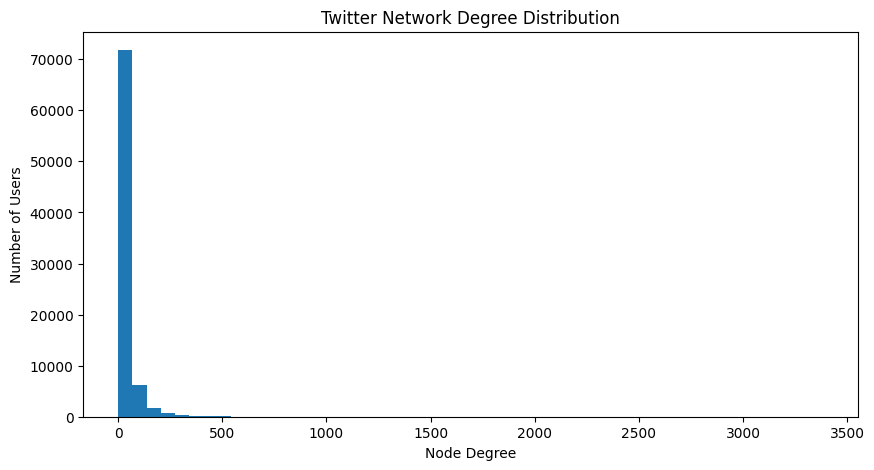

In [10]:
plt.figure(figsize=(10, 5))

plt.hist(
    degrees,
    bins=50
)

plt.xlabel("Node Degree")
plt.ylabel("Number of Users")
plt.title("Twitter Network Degree Distribution")

plt.show()

In [12]:
!pip install networkx pandas numpy scikit-learn python-louvain igraph leidenalg matplotlib

  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached pandas-3.0.5-cp314-cp314-win_amd64.whl.metadata (19 kB)
  Using cached numpy-2.5.3-cp314-cp314-win_amd64.whl.metadata (6.6 kB)
  Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached python-louvain-0.16.tar.gz (204 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached python_dateutil-2.9.0.post0-py2.py3-none-any.whl.metadata (8.4 kB)
  Using cached tzdata-2026.4-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-

ERROR: Could not install packages due to an OSError: ('Connection broken: IncompleteRead(215142 bytes read, 110872 more expected)', IncompleteRead(215142 bytes read, 110872 more expected))



In [13]:
import networkx as nx
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from community import community_louvain

from sklearn.cluster import SpectralClustering
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

import igraph as ig
import leidenalg

print("All libraries imported successfully!")

All libraries imported successfully!


In [14]:
DATASET_PATH = r"D:\GNN Mini project\twitter_combined.txt"

print("Dataset:", DATASET_PATH)

print("Loading Twitter dataset...")

G = nx.read_edgelist(
    DATASET_PATH,
    nodetype=int,
    create_using=nx.Graph()
)

# Remove self-connections
G.remove_edges_from(nx.selfloop_edges(G))

print("\n===== TWITTER GRAPH =====")
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("=========================")

Dataset: D:\GNN Mini project\twitter_combined.txt
Loading Twitter dataset...

===== TWITTER GRAPH =====
Nodes: 81306
Edges: 1342296


In [15]:
print("Running Louvain...")

louvain_partition = community_louvain.best_partition(
    G,
    random_state=42
)

print(
    "Louvain communities:",
    len(set(louvain_partition.values()))
)

Running Louvain...
Louvain communities: 75


In [16]:
print("Creating connected subgraph for Spectral Clustering...")

largest_component = max(
    nx.connected_components(G),
    key=len
)

largest_component_graph = G.subgraph(
    largest_component
).copy()

MAX_NODES = 5000

if largest_component_graph.number_of_nodes() > MAX_NODES:

    spectral_nodes = list(
        largest_component_graph.nodes()
    )[:MAX_NODES]

    G_spectral = largest_component_graph.subgraph(
        spectral_nodes
    ).copy()

else:

    G_spectral = largest_component_graph.copy()

print(
    "Spectral graph nodes:",
    G_spectral.number_of_nodes()
)

print(
    "Spectral graph edges:",
    G_spectral.number_of_edges()
)

Creating connected subgraph for Spectral Clustering...
Spectral graph nodes: 5000
Spectral graph edges: 92760


In [17]:
print("Running Spectral Clustering...")

N_CLUSTERS = 10

spectral_model = SpectralClustering(
    n_clusters=N_CLUSTERS,
    affinity="precomputed",
    assign_labels="kmeans",
    random_state=42
)

A = nx.to_numpy_array(G_spectral)

spectral_labels = spectral_model.fit_predict(A)

spectral_partition = dict(
    zip(
        G_spectral.nodes(),
        spectral_labels
    )
)

print(
    "Spectral communities:",
    len(set(spectral_labels))
)

Running Spectral Clustering...


c:\Users\admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


Spectral communities: 10


In [18]:
print("Converting NetworkX graph to igraph...")

nodes = list(G.nodes())

node_to_index = {
    node: index
    for index, node in enumerate(nodes)
}

edges = list(G.edges())

igraph_edges = [
    (
        node_to_index[u],
        node_to_index[v]
    )
    for u, v in edges
]

IG = ig.Graph(
    n=len(nodes),
    edges=igraph_edges
)

print("igraph graph created.")
print("Nodes:", IG.vcount())
print("Edges:", IG.ecount())

Converting NetworkX graph to igraph...
igraph graph created.
Nodes: 81306
Edges: 1342296


In [19]:
print("Running Leiden...")

leiden_result = leidenalg.find_partition(
    IG,
    leidenalg.ModularityVertexPartition,
    seed=42
)

leiden_labels = leiden_result.membership

leiden_partition = {
    nodes[i]: leiden_labels[i]
    for i in range(len(nodes))
}

print(
    "Leiden communities:",
    len(set(leiden_labels))
)

Running Leiden...
Leiden communities: 69


In [20]:
community_df = pd.DataFrame({
    "node": list(G.nodes())
})

community_df["louvain"] = (
    community_df["node"]
    .map(louvain_partition)
)

community_df["leiden"] = (
    community_df["node"]
    .map(leiden_partition)
)

community_df["spectral"] = (
    community_df["node"]
    .map(spectral_partition)
)

community_df.head(20)

,node,louvain,leiden,spectral
0,214328887,57,2,8.0
1,34428380,57,2,8.0
2,17116707,57,2,8.0
3,28465635,57,2,8.0
4,380580781,57,2,8.0
5,18996905,57,2,8.0
6,221036078,57,2,8.0
7,153460275,57,2,8.0
8,107830991,57,2,8.0
9,17868918,57,2,8.0


In [21]:
print("Creating connectivity features...")

# Calculate Louvain community sizes
louvain_sizes = (
    community_df["louvain"]
    .value_counts()
    .to_dict()
)

features = []

for node in G.nodes():

    degree = G.degree(node)

    louvain_community = louvain_partition[node]

    internal_louvain = 0
    external_louvain = 0

    for neighbor in G.neighbors(node):

        if (
            louvain_partition[neighbor]
            == louvain_community
        ):
            internal_louvain += 1

        else:
            external_louvain += 1

    if degree > 0:

        internal_ratio = (
            internal_louvain / degree
        )

        cross_ratio = (
            external_louvain / degree
        )

    else:

        internal_ratio = 0
        cross_ratio = 0

    clustering = nx.clustering(
        G,
        node
    )

    features.append({

        "node": node,

        "degree": degree,

        "louvain_community":
            louvain_community,

        "louvain_community_size":
            louvain_sizes[
                louvain_community
            ],

        "internal_connections":
            internal_louvain,

        "external_connections":
            external_louvain,

        "internal_ratio":
            internal_ratio,

        "cross_community_ratio":
            cross_ratio,

        "clustering_coefficient":
            clustering
    })

features_df = pd.DataFrame(features)

print("Feature extraction completed!")

features_df.head()

Creating connectivity features...
Feature extraction completed!


,node,degree,louvain_community,louvain_community_size,internal_connections,external_connections,internal_ratio,cross_community_ratio,clustering_coefficient
0,214328887,284,57,6146,283,1,0.996479,0.003521,0.353556
1,34428380,2476,57,6146,2452,24,0.990307,0.009693,0.028234
2,17116707,257,57,6146,257,0,1.000000,0.000000,0.249666
3,28465635,719,57,6146,704,15,0.979138,0.020862,0.088474
4,380580781,306,57,6146,306,0,1.000000,0.000000,0.274638


In [22]:
features_df["spectral_community"] = (
    features_df["node"]
    .map(spectral_partition)
)

features_df["leiden_community"] = (
    features_df["node"]
    .map(leiden_partition)
)

features_df.head()

,node,degree,louvain_community,louvain_community_size,internal_connections,external_connections,internal_ratio,cross_community_ratio,clustering_coefficient,spectral_community,leiden_community
0,214328887,284,57,6146,283,1,0.996479,0.003521,0.353556,8.0,2
1,34428380,2476,57,6146,2452,24,0.990307,0.009693,0.028234,8.0,2
2,17116707,257,57,6146,257,0,1.000000,0.000000,0.249666,8.0,2
3,28465635,719,57,6146,704,15,0.979138,0.020862,0.088474,8.0,2
4,380580781,306,57,6146,306,0,1.000000,0.000000,0.274638,8.0,2


In [23]:
features_df["spectral_available"] = (
    features_df["spectral_community"]
    .notna()
    .astype(int)
)

print(
    features_df[
        "spectral_available"
    ].value_counts()
)

spectral_available
0    76306
1     5000
Name: count, dtype: int64


In [24]:
spam_features = [

    "degree",

    "louvain_community_size",

    "internal_connections",

    "external_connections",

    "internal_ratio",

    "cross_community_ratio",

    "clustering_coefficient"
]

X = features_df[
    spam_features
].fillna(0)

print("Spam feature matrix:")
print(X.shape)

Spam feature matrix:
(81306, 7)


In [25]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(
    "Normalized feature matrix:",
    X_scaled.shape
)

Normalized feature matrix: (81306, 7)


In [26]:
print("Running anomaly detection...")

isolation_model = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)

predictions = isolation_model.fit_predict(
    X_scaled
)

anomaly_scores = (
    isolation_model
    .decision_function(X_scaled)
)

print("Anomaly detection completed.")

Running anomaly detection...
Anomaly detection completed.


In [27]:
features_df["anomaly_score"] = (
    anomaly_scores
)

features_df["spam_prediction"] = np.where(
    predictions == -1,
    "Potential Spam",
    "Normal"
)

print(
    features_df[
        "spam_prediction"
    ].value_counts()
)

spam_prediction
Normal            77240
Potential Spam     4066
Name: count, dtype: int64


In [28]:
potential_spam = features_df[
    features_df["spam_prediction"]
    == "Potential Spam"
].copy()

potential_spam = potential_spam.sort_values(
    "anomaly_score"
)

potential_spam.head(20)

,node,degree,louvain_community,louvain_community_size,internal_connections,external_connections,internal_ratio,cross_community_ratio,clustering_coefficient,spectral_community,leiden_community,spectral_available,anomaly_score,spam_prediction
1550,813286,3011,50,10607,851,2160,0.282630,0.717370,0.005735,0.0,1,1,-0.227298,Potential Spam
2413,17093617,1358,31,2413,290,1068,0.213549,0.786451,0.010658,0.0,7,1,-0.213796,Potential Spam
436,7861312,2155,50,10607,886,1269,0.411137,0.588863,0.013878,0.0,1,1,-0.213110,Potential Spam
501,15439395,1220,50,10607,417,803,0.341803,0.658197,0.015778,0.0,1,1,-0.212299,Potential Spam
554,10350,1180,38,1621,368,812,0.311864,0.688136,0.032643,0.0,10,1,-0.211363,Potential Spam
3270,428333,1256,18,1040,302,954,0.240446,0.759554,0.016524,0.0,23,1,-0.210824,Potential Spam
2774,62581962,1198,50,10607,410,788,0.342237,0.657763,0.007199,0.0,1,1,-0.210085,Potential Spam
11009,15846407,1229,50,10607,475,754,0.386493,0.613507,0.021101,NaN,1,0,-0.209602,Potential Spam
572,1183041,1666,50,10607,729,937,0.437575,0.562425,0.015682,0.0,1,1,-0.208256,Potential Spam
1643,16303106,1521,50,10607,627,894,0.412229,0.587771,0.009933,0.0,1,1,-0.207988,Potential Spam


In [29]:
columns_to_show = [

    "node",

    "degree",

    "louvain_community",

    "louvain_community_size",

    "internal_connections",

    "external_connections",

    "internal_ratio",

    "cross_community_ratio",

    "clustering_coefficient",

    "anomaly_score",

    "spam_prediction"
]

potential_spam[
    columns_to_show
].head(20)

,node,degree,louvain_community,louvain_community_size,internal_connections,external_connections,internal_ratio,cross_community_ratio,clustering_coefficient,anomaly_score,spam_prediction
1550,813286,3011,50,10607,851,2160,0.282630,0.717370,0.005735,-0.227298,Potential Spam
2413,17093617,1358,31,2413,290,1068,0.213549,0.786451,0.010658,-0.213796,Potential Spam
436,7861312,2155,50,10607,886,1269,0.411137,0.588863,0.013878,-0.213110,Potential Spam
501,15439395,1220,50,10607,417,803,0.341803,0.658197,0.015778,-0.212299,Potential Spam
554,10350,1180,38,1621,368,812,0.311864,0.688136,0.032643,-0.211363,Potential Spam
3270,428333,1256,18,1040,302,954,0.240446,0.759554,0.016524,-0.210824,Potential Spam
2774,62581962,1198,50,10607,410,788,0.342237,0.657763,0.007199,-0.210085,Potential Spam
11009,15846407,1229,50,10607,475,754,0.386493,0.613507,0.021101,-0.209602,Potential Spam
572,1183041,1666,50,10607,729,937,0.437575,0.562425,0.015682,-0.208256,Potential Spam
1643,16303106,1521,50,10607,627,894,0.412229,0.587771,0.009933,-0.207988,Potential Spam


In [30]:
counts = features_df[
    "spam_prediction"
].value_counts()

print("========== SPAM DETECTION ==========")

print(
    "Total users:",
    len(features_df)
)

print(
    "Normal users:",
    counts.get("Normal", 0)
)

print(
    "Potential Spam:",
    counts.get("Potential Spam", 0)
)

print("====================================")

========== SPAM DETECTION ==========
Total users: 81306
Normal users: 77240
Potential Spam: 4066


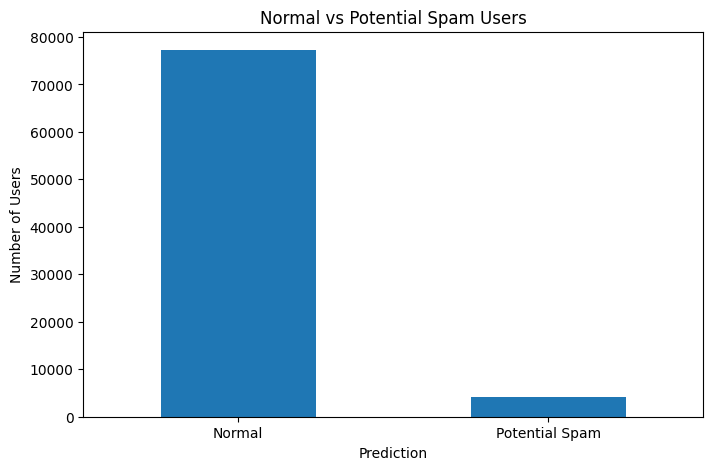

In [31]:
plt.figure(figsize=(8, 5))

counts.plot(
    kind="bar"
)

plt.title(
    "Normal vs Potential Spam Users"
)

plt.xlabel("Prediction")

plt.ylabel("Number of Users")

plt.xticks(rotation=0)

plt.show()

In [33]:
OUTPUT_PATH = (
    r"D:\GNN Mini project"
    r"\twitter_spam_detection_results.csv"
)

features_df.to_csv(
    OUTPUT_PATH,
    index=False
)

print(
    "Results saved to:"
)

print(OUTPUT_PATH)

Results saved to:
D:\GNN Mini project\twitter_spam_detection_results.csv


In [2]:
%pip install networkx matplotlib numpy scikit-learn python-louvain python-igraph leidenalg

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 2.1/2.1 MB 12.5 MB/s  0:00:00
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ----- ---------------------------------- 1.3/9.5 MB 8.6 MB/s eta 0:00:01
   -------- ------------------------------- 2.1/9.5 MB 4.9 MB/s eta 0:00:02
   --------- ------------------------------ 2.4/9.5 MB 4.3 MB/s eta 0:00:02
   ------------ --------------------------- 2.9/9.5 MB 3.4 MB/s eta 0:00:02
   ------------- -------------------------- 3.1/9.5 MB 3.1 MB/s eta 0:00:03
   --------------- ------------------------ 3.7/9.5 MB 2.9 MB/s eta 0:00:03
  

In [3]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

print("NetworkX version:", nx.__version__)
print("All basic packages are working!")

NetworkX version: 3.7
All basic packages are working!


CLEAR COMMUNITY VISUALIZATION

Loading Twitter dataset...
Full graph: 81306 nodes, 1342310 edges

Finding largest connected component...
Largest connected component: 81306 nodes, 1342310 edges

Selecting graph for visualization...

Final graph:
Nodes: 5000
Edges: 105272
Average degree: 42.11


RUNNING LOUVAIN

LOUVAIN CLEAR COMMUNITY VISUALIZATION
Communities detected: 5

Community sizes:
Community 1: 2,640 nodes
Community 2: 858 nodes
Community 3: 818 nodes
Community 4: 654 nodes
Community 5: 30 nodes

Finding inter-community connections...
Inter-community connections: 886


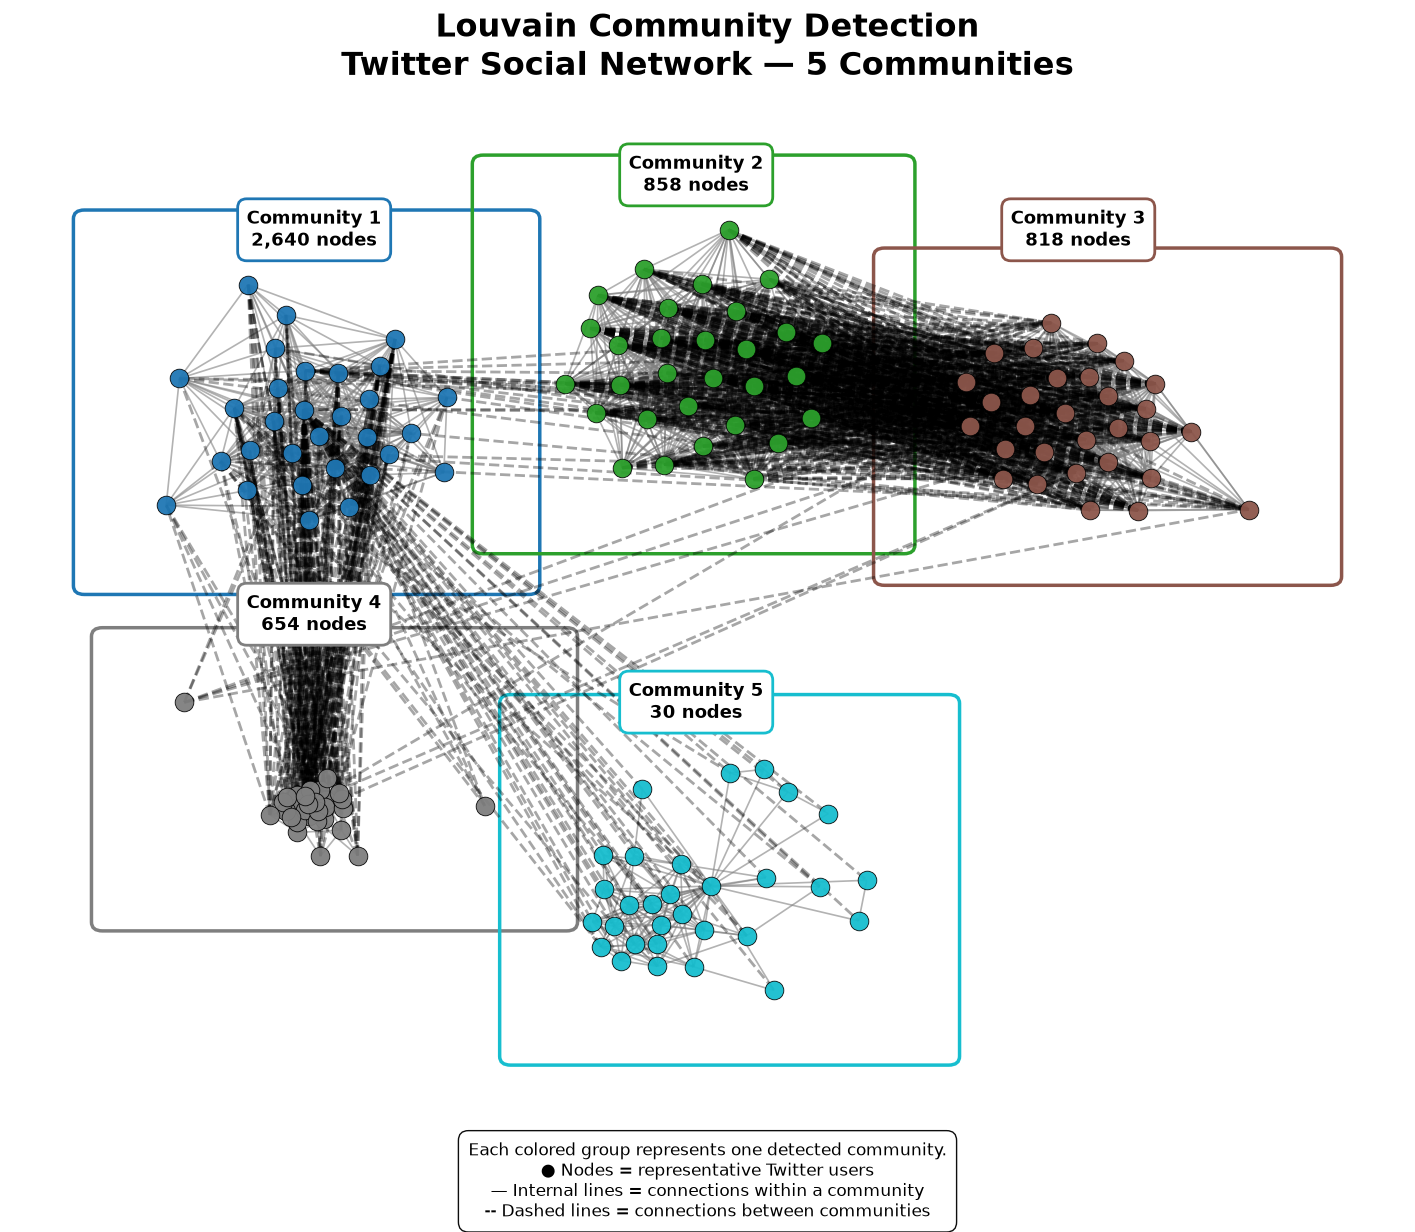


Saved: D:\GNN Mini project\FINAL_RESULTS\Louvain_Clear_Communities.png


RUNNING SPECTRAL CLUSTERING
Spectral communities: 5
Creating adjacency matrix...

SPECTRAL CLUSTERING CLEAR COMMUNITY VISUALIZATION
Communities detected: 5

Community sizes:
Community 1: 2,667 nodes
Community 2: 1,686 nodes
Community 3: 550 nodes
Community 4: 71 nodes
Community 5: 26 nodes

Finding inter-community connections...
Inter-community connections: 328


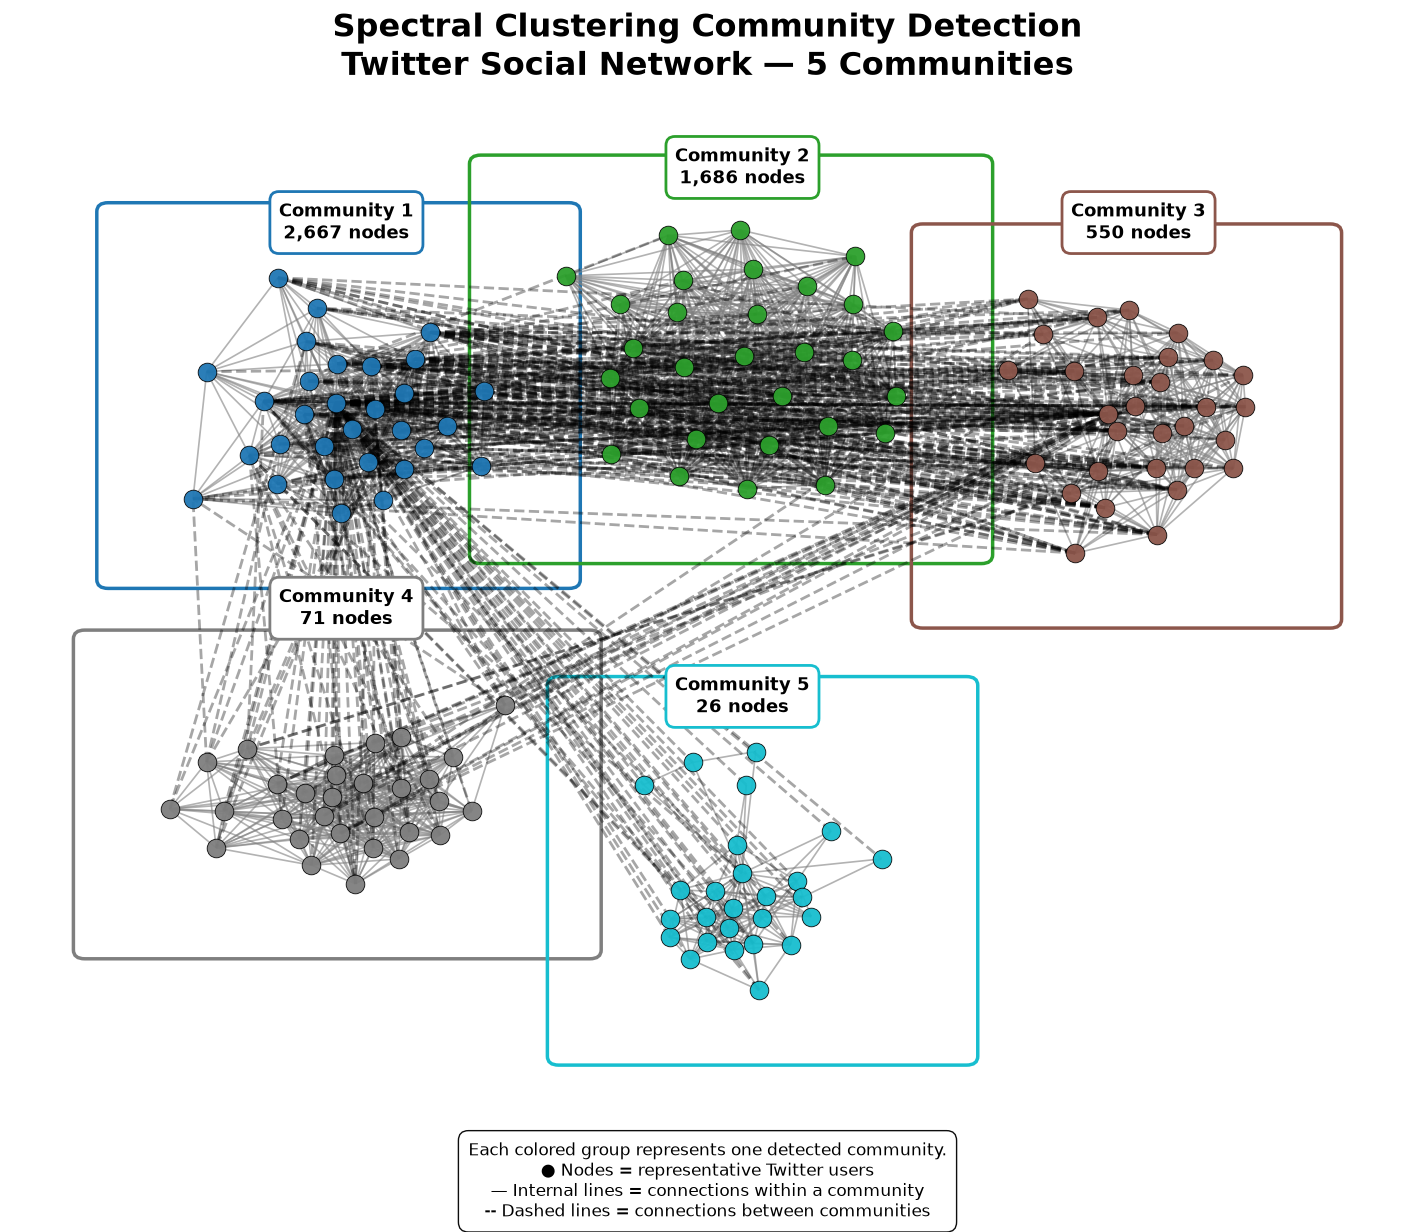


Saved: D:\GNN Mini project\FINAL_RESULTS\Spectral_Clear_5_Communities.png


RUNNING LEIDEN
Converting graph to igraph...
Running Leiden...

LEIDEN CLEAR COMMUNITY VISUALIZATION
Communities detected: 8

Community sizes:
Community 1: 2,631 nodes
Community 2: 1,002 nodes
Community 3: 620 nodes
Community 4: 612 nodes
Community 5: 57 nodes
Community 6: 34 nodes
Community 7: 26 nodes
Community 8: 18 nodes

Finding inter-community connections...
Inter-community connections: 1236


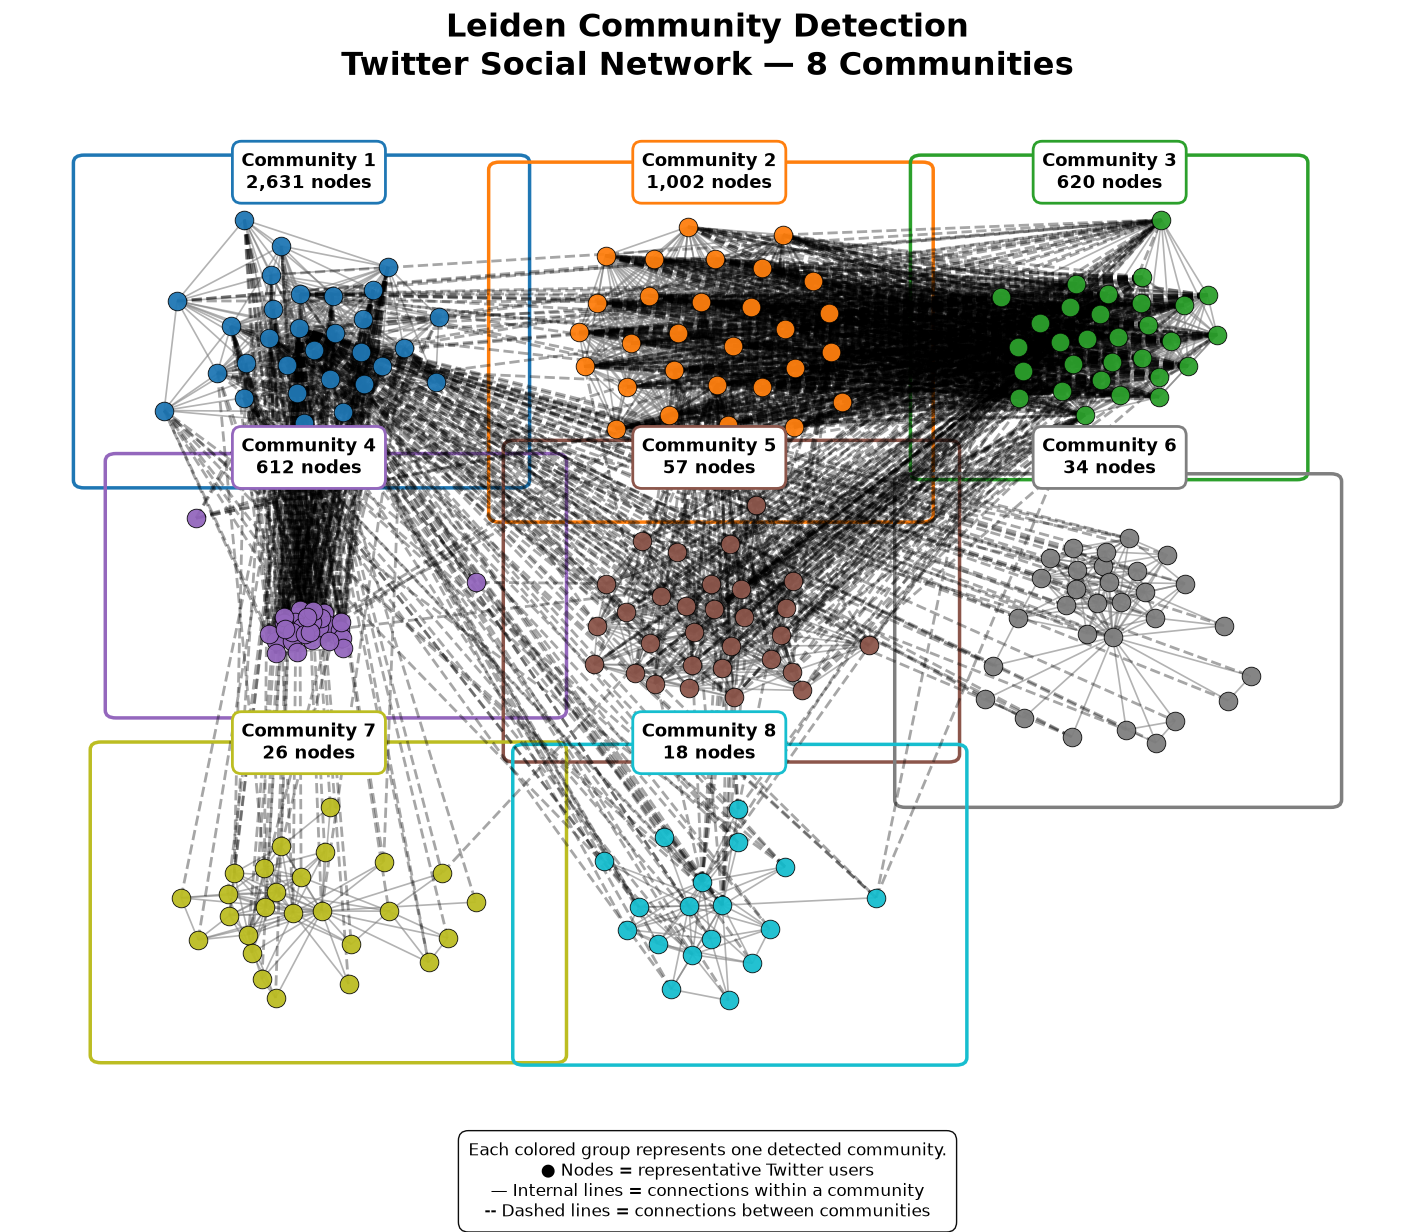


Saved: D:\GNN Mini project\FINAL_RESULTS\Leiden_Clear_Communities.png


ALL COMMUNITY VISUALIZATIONS COMPLETED

Files generated:
1. Louvain_Clear_Communities.png
2. Spectral_Clear_5_Communities.png
3. Leiden_Clear_Communities.png

Location:
D:\GNN Mini project\FINAL_RESULTS

Done!


In [6]:
# ============================================================
# CLEAR COMMUNITY GROUP VISUALIZATION
# ============================================================

import os
import warnings

warnings.filterwarnings("ignore")

import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

from matplotlib.patches import FancyBboxPatch
from sklearn.cluster import SpectralClustering

import community.community_louvain as community_louvain

import igraph as ig
import leidenalg


# ============================================================
# SETTINGS
# ============================================================

DATASET_PATH = r"D:\GNN Mini project\twitter_combined.txt"

OUTPUT_DIR = r"D:\GNN Mini project\FINAL_RESULTS"

MAX_NODES = 5000

REPRESENTATIVE_NODES = 30

RANDOM_SEED = 42

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ============================================================
# LOAD DATASET
# ============================================================

print("=" * 75)
print("CLEAR COMMUNITY VISUALIZATION")
print("=" * 75)

print("\nLoading Twitter dataset...")

G_full = nx.read_edgelist(
    DATASET_PATH,
    nodetype=int
)

print(
    "Full graph:",
    G_full.number_of_nodes(),
    "nodes,",
    G_full.number_of_edges(),
    "edges"
)


# ============================================================
# LARGEST CONNECTED COMPONENT
# ============================================================

print("\nFinding largest connected component...")

largest_component = max(
    nx.connected_components(G_full),
    key=len
)

G_connected = G_full.subgraph(
    largest_component
).copy()

print(
    "Largest connected component:",
    G_connected.number_of_nodes(),
    "nodes,",
    G_connected.number_of_edges(),
    "edges"
)


# ============================================================
# SELECT 5000 CONNECTED NODES
# ============================================================

print("\nSelecting graph for visualization...")

if G_connected.number_of_nodes() > MAX_NODES:

    start_node = max(
        G_connected.degree,
        key=lambda x: x[1]
    )[0]

    bfs_nodes = list(
        nx.bfs_tree(
            G_connected,
            start_node
        ).nodes()
    )

    selected_nodes = bfs_nodes[:MAX_NODES]

    G = G_connected.subgraph(
        selected_nodes
    ).copy()

else:

    G = G_connected.copy()


# ============================================================
# MAKE SURE GRAPH IS CONNECTED
# ============================================================

if G.number_of_nodes() > 0 and not nx.is_connected(G):

    largest = max(
        nx.connected_components(G),
        key=len
    )

    G = G.subgraph(
        largest
    ).copy()


print("\nFinal graph:")
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

if G.number_of_nodes() > 0:

    print(
        "Average degree:",
        round(
            sum(dict(G.degree()).values())
            / G.number_of_nodes(),
            2
        )
    )


# ============================================================
# FUNCTION
# CREATE CLEAR COMMUNITY VISUALIZATION
# ============================================================

def create_clear_visualization(
    G,
    partition,
    algorithm_name,
    output_filename
):

    print("\n" + "=" * 75)

    print(
        algorithm_name.upper(),
        "CLEAR COMMUNITY VISUALIZATION"
    )

    print("=" * 75)


    # ========================================================
    # ORGANIZE NODES BY COMMUNITY
    # ========================================================

    communities = {}

    for node, community_id in partition.items():

        if community_id not in communities:

            communities[community_id] = []

        communities[community_id].append(node)


    # ========================================================
    # REMOVE NODES NOT IN GRAPH
    # ========================================================

    communities = {

        cid: [
            node for node in nodes
            if node in G
        ]

        for cid, nodes in communities.items()

    }

    communities = {

        cid: nodes

        for cid, nodes in communities.items()

        if len(nodes) > 0

    }


    # ========================================================
    # SORT COMMUNITIES BY SIZE
    # ========================================================

    communities = dict(
        sorted(
            communities.items(),
            key=lambda x: len(x[1]),
            reverse=True
        )
    )


    community_list = list(
        communities.keys()
    )

    number_of_communities = len(
        community_list
    )


    print(
        "Communities detected:",
        number_of_communities
    )


    # ========================================================
    # PRINT COMMUNITY SIZES
    # ========================================================

    print("\nCommunity sizes:")

    for i, community_id in enumerate(
        community_list
    ):

        print(
            f"Community {i + 1}: "
            f"{len(communities[community_id]):,} nodes"
        )


    # ========================================================
    # REPRESENTATIVE NODES
    # ========================================================

    representative_nodes = {}

    for community_id in community_list:

        community_nodes = communities[
            community_id
        ]

        sorted_nodes = sorted(
            community_nodes,
            key=lambda node: G.degree(node),
            reverse=True
        )

        selected = sorted_nodes[
            :REPRESENTATIVE_NODES
        ]

        representative_nodes[
            community_id
        ] = selected


    # ========================================================
    # CREATE FIGURE
    # ========================================================

    fig, ax = plt.subplots(
        figsize=(18, 13)
    )


    # ========================================================
    # COMMUNITY POSITIONS
    # ========================================================

    base_positions = [

        (-2.8, 2.0),

        (0.0, 2.5),

        (2.8, 2.0),

        (-2.8, -1.5),

        (0.0, -2.3),

        (2.8, -1.5)

    ]


    if number_of_communities <= 6:

        community_positions = {

            i: base_positions[i]

            for i in range(
                number_of_communities
            )

        }

    else:

        community_positions = {}

        columns = 3

        spacing_x = 3.0

        spacing_y = 3.0

        for i in range(
            number_of_communities
        ):

            row = i // columns

            col = i % columns

            x = (
                (col - 1)
                * spacing_x
            )

            y = (
                2.5
                - row * spacing_y
            )

            community_positions[i] = (
                x,
                y
            )


    # ========================================================
    # COLORS
    # ========================================================

    if number_of_communities <= 10:

        cmap = plt.colormaps.get_cmap(
            "tab10"
        )

    else:

        cmap = plt.colormaps.get_cmap(
            "tab20"
        )


    # ========================================================
    # STORE NODE POSITIONS
    # ========================================================

    final_positions = {}


    # ========================================================
    # DRAW EACH COMMUNITY
    # ========================================================

    for community_index, community_id in enumerate(
        community_list
    ):

        selected_nodes = representative_nodes[
            community_id
        ]

        if len(selected_nodes) == 0:
            continue


        center_x, center_y = community_positions[
            community_index
        ]


        # ====================================================
        # CREATE SUBGRAPH
        # ====================================================

        subgraph = G.subgraph(
            selected_nodes
        ).copy()


        # ====================================================
        # LOCAL SPRING LAYOUT
        # ====================================================

        if len(selected_nodes) > 1:

            local_pos = nx.spring_layout(
                subgraph,
                seed=RANDOM_SEED,
                k=0.7,
                iterations=100
            )

        else:

            local_pos = {

                selected_nodes[0]:
                np.array(
                    [0.0, 0.0]
                )

            }


        # ====================================================
        # MOVE COMMUNITY
        # ====================================================

        for node, coordinates in local_pos.items():

            x = (
                coordinates[0] * 1.25
                + center_x
            )

            y = (
                coordinates[1] * 1.25
                + center_y
            )

            final_positions[node] = (
                x,
                y
            )


        # ====================================================
        # COMMUNITY COLOR
        # ====================================================

        color_index = (

            community_index
            / max(
                1,
                number_of_communities - 1
            )

        )

        community_color = cmap(
            color_index
        )


        # ====================================================
        # INTERNAL EDGES
        # ====================================================

        nx.draw_networkx_edges(
            subgraph,
            final_positions,
            ax=ax,
            edge_color="gray",
            alpha=0.60,
            width=1.2
        )


        # ====================================================
        # NODES
        # ====================================================

        nx.draw_networkx_nodes(
            subgraph,
            final_positions,
            ax=ax,
            node_color=[
                community_color
            ],
            node_size=180,
            alpha=0.95,
            edgecolors="black",
            linewidths=0.6
        )


        # ====================================================
        # COMMUNITY BOUNDARY
        # ====================================================

        xs = [

            final_positions[node][0]

            for node in selected_nodes

            if node in final_positions

        ]

        ys = [

            final_positions[node][1]

            for node in selected_nodes

            if node in final_positions

        ]


        if len(xs) > 2:

            min_x = min(xs)

            max_x = max(xs)

            min_y = min(ys)

            max_y = max(ys)


            width = (
                max_x
                - min_x
                + 1.2
            )

            height = (
                max_y
                - min_y
                + 1.2
            )


            box = FancyBboxPatch(

                (
                    min_x - 0.6,
                    min_y - 0.6
                ),

                width,

                height,

                boxstyle=(
                    "round,pad=0.08"
                ),

                fill=False,

                linewidth=2.5,

                edgecolor=community_color

            )

            ax.add_patch(
                box
            )


        # ====================================================
        # COMMUNITY LABEL
        # ====================================================

        label = (

            f"Community "
            f"{community_index + 1}\n"

            f"{len(communities[community_id]):,} nodes"

        )


        ax.text(

            center_x,

            center_y + 1.75,

            label,

            ha="center",

            va="center",

            fontsize=13,

            fontweight="bold",

            bbox=dict(

                boxstyle=(
                    "round,pad=0.5"
                ),

                facecolor="white",

                edgecolor=community_color,

                linewidth=2

            )

        )


    # ========================================================
    # INTER-COMMUNITY CONNECTIONS
    # ========================================================

    print(
        "\nFinding inter-community connections..."
    )


    intercommunity_edges = []

    representative_set = set()


    for selected in representative_nodes.values():

        representative_set.update(
            selected
        )


    for u, v in G.edges():

        if (

            u in representative_set

            and

            v in representative_set

        ):

            cu = partition[u]

            cv = partition[v]

            if cu != cv:

                if (

                    u in final_positions

                    and

                    v in final_positions

                ):

                    intercommunity_edges.append(
                        (u, v)
                    )


    print(
        "Inter-community connections:",
        len(intercommunity_edges)
    )


    # ========================================================
    # DRAW INTER-COMMUNITY EDGES
    # ========================================================

    if len(intercommunity_edges) > 0:

        nx.draw_networkx_edges(

            G,

            final_positions,

            edgelist=intercommunity_edges,

            ax=ax,

            edge_color="black",

            alpha=0.35,

            width=2.0,

            style="dashed"

        )


    # ========================================================
    # TITLE
    # ========================================================

    ax.set_title(

        f"{algorithm_name} Community Detection\n"

        f"Twitter Social Network — "

        f"{number_of_communities} Communities",

        fontsize=23,

        fontweight="bold",

        pad=25

    )


    # ========================================================
    # EXPLANATION
    # ========================================================

    explanation = (

        "Each colored group represents one detected community.\n"

        "● Nodes = representative Twitter users\n"

        "— Internal lines = connections within a community\n"

        "-- Dashed lines = connections between communities"

    )


    ax.text(

        0.5,

        -0.03,

        explanation,

        transform=ax.transAxes,

        ha="center",

        va="top",

        fontsize=12,

        bbox=dict(

            boxstyle=(
                "round,pad=0.6"
            ),

            facecolor="white",

            edgecolor="black",

            alpha=0.95

        )

    )


    # ========================================================
    # REMOVE AXES
    # ========================================================

    ax.set_axis_off()


    # ========================================================
    # SAVE
    # ========================================================

    output_path = os.path.join(

        OUTPUT_DIR,

        output_filename

    )


    plt.savefig(

        output_path,

        dpi=300,

        bbox_inches="tight",

        facecolor="white"

    )


    plt.show()

    plt.close()


    print(
        "\nSaved:",
        output_path
    )


# ============================================================
# 1. LOUVAIN
# ============================================================

print("\n")
print("=" * 75)
print("RUNNING LOUVAIN")
print("=" * 75)


louvain_partition = (

    community_louvain.best_partition(

        G,

        random_state=RANDOM_SEED

    )

)


create_clear_visualization(

    G,

    louvain_partition,

    "Louvain",

    "Louvain_Clear_Communities.png"

)


# ============================================================
# 2. SPECTRAL CLUSTERING
# ============================================================

print("\n")
print("=" * 75)
print("RUNNING SPECTRAL CLUSTERING")
print("=" * 75)


nodes = list(
    G.nodes()
)


SPECTRAL_K = 5


print(
    "Spectral communities:",
    SPECTRAL_K
)


print(
    "Creating adjacency matrix..."
)


A = nx.to_numpy_array(

    G,

    nodelist=nodes,

    dtype=np.float32

)


spectral_model = SpectralClustering(

    n_clusters=SPECTRAL_K,

    affinity="precomputed",

    assign_labels="kmeans",

    random_state=RANDOM_SEED

)


spectral_labels = (

    spectral_model.fit_predict(A)

)


spectral_partition = {

    node: int(label)

    for node, label

    in zip(

        nodes,

        spectral_labels

    )

}


create_clear_visualization(

    G,

    spectral_partition,

    "Spectral Clustering",

    "Spectral_Clear_5_Communities.png"

)


# ============================================================
# 3. LEIDEN
# ============================================================

print("\n")
print("=" * 75)
print("RUNNING LEIDEN")
print("=" * 75)


print(
    "Converting graph to igraph..."
)


igraph_graph = ig.Graph.TupleList(

    G.edges(),

    directed=False

)


print(
    "Running Leiden..."
)


leiden_result = leidenalg.find_partition(

    igraph_graph,

    leidenalg.ModularityVertexPartition,

    seed=RANDOM_SEED

)


igraph_names = (

    igraph_graph.vs["name"]

)


leiden_partition = {

    int(node): int(community)

    for node, community

    in zip(

        igraph_names,

        leiden_result.membership

    )

}


create_clear_visualization(

    G,

    leiden_partition,

    "Leiden",

    "Leiden_Clear_Communities.png"

)


# ============================================================
# FINAL
# ============================================================

print("\n")
print("=" * 75)
print("ALL COMMUNITY VISUALIZATIONS COMPLETED")
print("=" * 75)


print("\nFiles generated:")

print(
    "1. Louvain_Clear_Communities.png"
)

print(
    "2. Spectral_Clear_5_Communities.png"
)

print(
    "3. Leiden_Clear_Communities.png"
)


print(
    "\nLocation:"
)

print(
    OUTPUT_DIR
)

print("\nDone!")